# EAViT on 15-class Indian folk music

Implementation of *EAViT: External Attention Vision Transformer for Audio Classification*
(arXiv:2408.13201) for a 15-style Indian folk mel-spectrogram collection, with the
paper's evaluation protocol plus the leakage controls the original omits.

**Before running:** attach your dataset in the right-hand panel and switch the
accelerator to GPU (P100 or T4). Everything else is automatic - the dataset path is
detected, and nothing is downloaded.

Run order: setup -> self-test -> prepare -> train EAViT -> train ViT baseline -> compare.

## 0. Write the package

In [1]:
import os, pathlib
for d in ["eavit_folk", "eavit_folk/data", "eavit_folk/models", "eavit_folk/engine"]:
    pathlib.Path("/kaggle/working/src", d).mkdir(parents=True, exist_ok=True)
print("package directories ready under /kaggle/working/src")

package directories ready under /kaggle/working/src


In [2]:
%%writefile /kaggle/working/src/eavit_folk/__init__.py
"""EAViT for 15-class Indian folk music classification.

    from eavit_folk import Experiment, run_experiment
    exp = Experiment()
    exp.prep.root = "/kaggle/input/<slug>"
    summary = run_experiment(exp)

Torch is imported lazily, so the cleaning/splitting stage also runs on a CPU-only
kernel or a plain Python environment.
"""
import importlib

from .config import CacheConfig, Experiment, ModelConfig, PrepConfig, TrainConfig

__version__ = "1.0.0"

_LAZY = {
    "run_experiment": "pipeline", "run_prepare": "pipeline", "run_training": "pipeline",
    "compare": "pipeline", "evaluate_checkpoint": "pipeline", "show_environment": "pipeline",
    "prepare": "data.prepare", "load_prepared": "data.prepare",
    "Trainer": "engine.trainer", "build_model": "models.eavit",
}

__all__ = ["Experiment", "PrepConfig", "CacheConfig", "ModelConfig", "TrainConfig", *_LAZY]


def __getattr__(name):
    if name in _LAZY:
        module = importlib.import_module(f".{_LAZY[name]}", __name__)
        value = getattr(module, name)
        globals()[name] = value
        return value
    raise AttributeError(f"module {__name__!r} has no attribute {name!r}")


def __dir__():
    return sorted(__all__)


Writing /kaggle/working/src/eavit_folk/__init__.py


In [3]:
%%writefile /kaggle/working/src/eavit_folk/config.py
"""Typed configuration for every stage. Edit these in a notebook cell instead of
passing a wall of CLI flags."""
from __future__ import annotations

from dataclasses import asdict, dataclass, field
from typing import Optional, Sequence


@dataclass
class PrepConfig:
    """Stage 1: scan, clean, split."""
    root: str = "/kaggle/input/datasets/mishbhaul/pre-processed-indian-folk-music"                      # dataset root; "" = autodetect under /kaggle/input
    out: str = "/kaggle/working/prep"

    # segment decimation. Segments are 3 s with a 0.5 s hop, so consecutive
    # segments overlap by 2.5 s. stride=6 keeps only non-overlapping segments.
    stride: int = 1

    # corruption thresholds
    min_std: float = 1e-3               # below this a segment is constant -> corrupt
    max_abs: float = 1e4                # absurd magnitude -> corrupt
    min_segments_per_song: int = 8      # drop songs left with fewer clean segments

    # class subsetting. 0 = keep every style. Any other value keeps the k styles with
    # the most segments AFTER cleaning and striding, and drops the rest. The criterion
    # is data scarcity, decided before any model is trained, so it cannot be tuned on
    # results - state it in the write-up exactly as it is.
    keep_top_k_classes: int = 10

    # splitting
    group_key: str = "song"             # song | artist | none  ("none" = paper-style, leaky)
    val_size: float = 0.15
    test_size: float = 0.15

    chunk: int = 4096                   # segments per corruption-scan block
    stats_sample: int = 60000           # segments used for the train mean/std
    seed: int = 42


@dataclass
class CacheConfig:
    """Stage 1b: pack the kept segments into one contiguous float16 array.

    Random reads across a 25 GB dataset on /kaggle/input are slow; one sequential
    pass into a compact cache makes every epoch afterwards disk-free."""
    enabled: bool = True
    path: str = "/kaggle/working/cache/segments.f16.npy"
    dtype: str = "float16"
    in_ram: bool = True                 # load the cache fully into RAM if it fits
    ram_budget_gb: float = 8.0          # refuse to load into RAM above this


@dataclass
class ModelConfig:
    """Section III-A of the paper."""
    attention: str = "mea"              # mea = EAViT, mhsa = plain ViT baseline
    dim: int = 32                       # projection dimension
    depth: int = 16                     # transformer layers
    num_heads: int = 8
    mlp_ratio: float = 2.0              # encoder MLP width = mlp_ratio * dim
    memory_size: int = 64               # S, shared learnable memory units in MEA
    head_hidden: Sequence[int] = (2048, 1024)
    drop: float = 0.1
    head_drop: float = 0.5
    patch_grid: Sequence[int] = (4, 4)  # 4x4 = the paper's 16 patches
    img_size: Optional[Sequence[int]] = None   # None = native segment shape


@dataclass
class TrainConfig:
    out: str = "/kaggle/working/runs/eavit"
    epochs: int = 100
    batch_size: int = 256
    lr: float = 1e-3
    weight_decay: float = 1e-4
    warmup_epochs: int = 5
    label_smoothing: float = 0.1
    clip_grad: float = 1.0
    balance: str = "weighted_loss"      # none | weighted_loss | sampler | both
    spec_augment: bool = True
    freq_mask: int = 16
    time_mask: int = 24
    n_masks: int = 2
    early_stop: int = 20                # epochs without val macro-F1 gain; 0 = off
    max_hours: float = 8.0              # stop cleanly before Kaggle kills the session
    resume: bool = True                 # continue from last.pt if the run directory exists
    amp: bool = True
    workers: int = -1                   # -1 = choose automatically
    seed: int = 42
    limit_per_class: int = 0            # smoke test: cap segments per class per split
    eval_song_level: bool = True


@dataclass
class Experiment:
    prep: PrepConfig = field(default_factory=PrepConfig)
    cache: CacheConfig = field(default_factory=CacheConfig)
    model: ModelConfig = field(default_factory=ModelConfig)
    train: TrainConfig = field(default_factory=TrainConfig)

    def to_dict(self) -> dict:
        return {k: asdict(v) for k, v in vars(self).items()}


Writing /kaggle/working/src/eavit_folk/config.py


In [4]:
%%writefile /kaggle/working/src/eavit_folk/utils.py
"""Environment probing, seeding, and small IO helpers. No torch import at module
level so stage 1 can run on a CPU-only kernel without pulling CUDA in."""
from __future__ import annotations

import json
import os
import random
import sys
import time
from pathlib import Path
from typing import Iterable

import numpy as np
import pandas as pd

KAGGLE_INPUT = Path("/kaggle/input")
KAGGLE_WORKING = Path("/kaggle/working")


# --------------------------------------------------------------------------- env
def is_kaggle() -> bool:
    return KAGGLE_INPUT.exists() or "KAGGLE_KERNEL_RUN_TYPE" in os.environ


def cpu_count() -> int:
    try:
        return len(os.sched_getaffinity(0))
    except AttributeError:
        return os.cpu_count() or 2


def ram_gb() -> float:
    try:
        return os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 1024 ** 3
    except (ValueError, OSError, AttributeError):
        return 16.0


def free_disk_gb(path="/kaggle/working") -> float:
    p = Path(path)
    while not p.exists() and p != p.parent:
        p = p.parent
    st = os.statvfs(p)
    return st.f_bavail * st.f_frsize / 1024 ** 3


def describe_environment() -> dict:
    info = {
        "kaggle": is_kaggle(),
        "python": sys.version.split()[0],
        "cpus": cpu_count(),
        "ram_gb": round(ram_gb(), 1),
        "free_disk_gb": round(free_disk_gb(), 1),
        "numpy": np.__version__,
        "pandas": pd.__version__,
    }
    try:
        import torch
        info["torch"] = torch.__version__
        info["cuda"] = torch.cuda.is_available()
        if torch.cuda.is_available():
            info["gpu"] = torch.cuda.get_device_name(0)
            info["gpu_count"] = torch.cuda.device_count()
            info["gpu_mem_gb"] = round(
                torch.cuda.get_device_properties(0).total_memory / 1024 ** 3, 1)
    except Exception as exc:                       # torch missing or broken
        info["torch"] = f"unavailable ({exc.__class__.__name__})"
    return info


def auto_workers(requested: int = -1) -> int:
    """Kaggle gives 2-4 usable cores. Oversubscribing dataloader workers there
    costs more in context switching than it buys."""
    if requested >= 0:
        return requested
    return max(0, min(4, cpu_count() - 1))


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    try:
        import torch
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.benchmark = True      # fixed shapes -> benchmark is free speed
    except Exception:
        pass


def get_device():
    import torch
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


# --------------------------------------------------------------------------- io
def ensure_dir(path) -> Path:
    p = Path(path)
    p.mkdir(parents=True, exist_ok=True)
    return p


def save_json(obj, path) -> None:
    ensure_dir(Path(path).parent)
    with open(path, "w") as fh:
        json.dump(obj, fh, indent=2, default=str)


def load_json(path) -> dict:
    with open(path) as fh:
        return json.load(fh)


def save_table(df: pd.DataFrame, path) -> Path:
    """Parquet when pyarrow is available, pickle otherwise. Kaggle ships pyarrow,
    but a local run should not fail over it."""
    path = Path(path)
    ensure_dir(path.parent)
    try:
        df.to_parquet(path, index=False)
        return path
    except Exception:
        alt = path.with_suffix(".pkl")
        df.to_pickle(alt)
        return alt


def load_table(path) -> pd.DataFrame:
    path = Path(path)
    if path.exists():
        try:
            return pd.read_parquet(path)
        except Exception:
            pass
    alt = path.with_suffix(".pkl")
    if alt.exists():
        return pd.read_pickle(alt)
    raise FileNotFoundError(f"neither {path} nor {alt} exists - run the prepare stage first")


# --------------------------------------------------------------------------- logging
class Timer:
    def __init__(self, label: str, quiet: bool = False):
        self.label, self.quiet = label, quiet

    def __enter__(self):
        self.t0 = time.time()
        if not self.quiet:
            print(f"[{self.label}] started")
        return self

    def __exit__(self, *exc):
        self.elapsed = time.time() - self.t0
        if not self.quiet:
            print(f"[{self.label}] done in {self.elapsed:,.1f}s")


def banner(text: str, width: int = 78) -> None:
    print("\n" + "=" * width)
    print(text)
    print("=" * width)


def frame_to_text(df: pd.DataFrame, **kw) -> str:
    with pd.option_context("display.max_rows", 200, "display.width", 200):
        return df.to_string(**kw)


def flatten(nested: Iterable) -> list:
    return [x for sub in nested for x in sub]


Writing /kaggle/working/src/eavit_folk/utils.py


In [5]:
%%writefile /kaggle/working/src/eavit_folk/data/__init__.py
"""Data stage. Torch-dependent names are imported lazily."""
import importlib

from .cache import build_cache, cache_plan, open_cache
from .prepare import load_prepared, prepare
from .scan import autodetect_root, discover
from .splits import assign_splits, leakage_report, split_summary

_LAZY = {"FolkSegments": "dataset", "build_loaders": "dataset", "class_weights": "dataset"}

__all__ = ["prepare", "load_prepared", "discover", "autodetect_root", "assign_splits",
           "leakage_report", "split_summary", "build_cache", "cache_plan", "open_cache",
           *_LAZY]


def __getattr__(name):
    if name in _LAZY:
        value = getattr(importlib.import_module(f".{_LAZY[name]}", __name__), name)
        globals()[name] = value
        return value
    raise AttributeError(f"module {__name__!r} has no attribute {name!r}")


Writing /kaggle/working/src/eavit_folk/data/__init__.py


In [6]:
%%writefile /kaggle/working/src/eavit_folk/data/scan.py
"""Discovery of (csv, npy) genre pairs and per-segment integrity scanning."""
from __future__ import annotations

import sys
from dataclasses import dataclass
from pathlib import Path
from typing import List, Tuple

import numpy as np
import pandas as pd

from ..utils import KAGGLE_INPUT

COLUMN_ALIASES = {
    "folk_style": "genre", "style": "genre", "class": "genre", "label": "genre",
    "singer": "artist", "performer": "artist",
    "track": "song", "title": "song", "song_name": "song",
    "sex": "gender",
}
REQUIRED = ("genre", "song", "artist", "gender", "state")


@dataclass
class GenreSource:
    genre: str
    csv: Path
    npy: Path


# --------------------------------------------------------------------------- discovery
def autodetect_root() -> Path:
    """Pick the Kaggle input dataset that actually looks like this collection."""
    if not KAGGLE_INPUT.exists():
        raise FileNotFoundError(
            "/kaggle/input does not exist - pass PrepConfig.root explicitly")
    candidates = []
    for entry in sorted(KAGGLE_INPUT.iterdir()):
        if not entry.is_dir():
            continue
        n_pairs = len(discover(entry, quiet=True))
        if n_pairs:
            candidates.append((n_pairs, entry))
    if not candidates:
        listing = ", ".join(p.name for p in KAGGLE_INPUT.iterdir()) or "(empty)"
        raise FileNotFoundError(
            f"no folder under /kaggle/input contains matching .csv/.npy pairs. Found: {listing}")
    candidates.sort(reverse=True)
    root = candidates[0][1]
    if len(candidates) > 1:
        print(f"[scan] multiple candidate datasets; using {root.name} "
              f"({candidates[0][0]} genre folders)")
    return root


def discover(root: Path, quiet: bool = False) -> List[GenreSource]:
    """Every .csv with a sibling .npy, anywhere under root. Handles the nested
    <Genre>/<Genre>/ layout Kaggle produces."""
    out: List[GenreSource] = []
    for csv in sorted(Path(root).rglob("*.csv")):
        stem = csv.stem
        candidates = [csv.with_name(f"{stem}_melspec.npy"),
                      csv.with_name(f"{stem}_melspecs.npy"),
                      csv.with_name(f"{stem}.npy")]
        npy = next((c for c in candidates if c.exists()), None)
        if npy is None:
            siblings = sorted(csv.parent.glob("*.npy"))
            npy = siblings[0] if len(siblings) == 1 else None
        if npy is None:
            if not quiet:
                print(f"[scan] no .npy beside {csv.name} - skipped", file=sys.stderr)
            continue
        out.append(GenreSource(genre=stem, csv=csv, npy=npy))
    return out


def normalise_columns(df: pd.DataFrame) -> pd.DataFrame:
    df = df.rename(columns={c: str(c).strip().lower() for c in df.columns})
    df = df.rename(columns={k: v for k, v in COLUMN_ALIASES.items()
                            if k in df.columns and v not in df.columns})
    for col in REQUIRED:
        if col not in df.columns:
            df[col] = "unknown"
        df[col] = df[col].astype(str).str.strip().replace({"": "unknown", "nan": "unknown"})
    return df


def npy_header(path: Path) -> Tuple[tuple, np.dtype]:
    """Read shape/dtype from the .npy header without mapping the payload."""
    with open(path, "rb") as fh:
        version = np.lib.format.read_magic(fh)
        shape, _, dtype = np.lib.format._read_array_header(fh, version)
    return shape, dtype


# --------------------------------------------------------------------------- integrity
def scan_segments(npy_path: Path, n_rows: int, chunk: int,
                  min_std: float, max_abs: float):
    """
    Block-wise integrity scan over a memory-mapped array.

    A segment is corrupt when it
      * holds NaN or +/-Inf,
      * is constant (std < min_std): silence, a zero-filled row, a truncated write,
      * exceeds max_abs: broken dtype or scaling.

    Returns (ok_mask, reason_array).
    """
    arr = np.load(npy_path, mmap_mode="r")
    if arr.ndim != 3:
        raise ValueError(f"{npy_path.name}: expected (N, n_mels, T), got {arr.shape}")
    n = min(n_rows, arr.shape[0])
    ok = np.ones(n, dtype=bool)
    reason = np.zeros(n, dtype="<U12")

    for start in range(0, n, chunk):
        stop = min(start + chunk, n)
        block = np.asarray(arr[start:stop], dtype=np.float32)
        finite = np.isfinite(block).all(axis=(1, 2))
        safe = np.where(finite[:, None, None], block, 0.0)
        std = safe.std(axis=(1, 2))
        amax = np.abs(safe).max(axis=(1, 2))

        bad_nan = ~finite
        bad_const = finite & (std < min_std)
        bad_range = finite & (amax > max_abs)
        idx = np.arange(start, stop)
        reason[idx[bad_nan]] = "nan_or_inf"
        reason[idx[bad_const]] = "constant"
        reason[idx[bad_range]] = "out_of_range"
        ok[start:stop] = ~(bad_nan | bad_const | bad_range)

    del arr
    return ok, reason


def decimate_by_song(meta: pd.DataFrame, stride: int, key: str = "song_key") -> np.ndarray:
    """
    Keep every stride-th segment within each song, in row order.

    Segments are 3 s long with a 0.5 s hop, so neighbours share 2.5 s of audio.
    stride=6 yields non-overlapping segments: ~6x less data, ~6x faster epochs,
    and it removes the near-duplicate segments that make a training set look
    larger than it is.
    """
    if stride <= 1:
        return np.ones(len(meta), dtype=bool)
    if key not in meta.columns:
        key = "song"
    keep = np.zeros(len(meta), dtype=bool)
    order = np.argsort(meta["row"].to_numpy(), kind="stable")
    for _, idx in meta.iloc[order].groupby(key, sort=False).indices.items():
        keep[order[np.asarray(idx)[::stride]]] = True
    return keep


Writing /kaggle/working/src/eavit_folk/data/scan.py


In [7]:
%%writefile /kaggle/working/src/eavit_folk/data/splits.py
"""Split assignment.

The paper splits GTZAN's 3 s segments at random, so segments cut from the same
recording sit on both sides of the split. With a 0.5 s hop that is worse here:
neighbouring segments share 2.5 s of audio, and a random split measures recording
memorisation rather than style recognition. Default is therefore a grouped split.
"""
from __future__ import annotations

from typing import Dict, List, Tuple

import numpy as np
import pandas as pd

SPLITS = ("train", "val", "test")
GROUP_COLUMNS = {"song": "song_key", "artist": "artist_key", "none": None}


def grouped_stratified_split(manifest: pd.DataFrame, group_col: str,
                             ratios: Dict[str, float], seed: int
                             ) -> Tuple[pd.Series, List[str]]:
    """
    Assign whole groups to splits, class by class, targeting the requested
    segment-level ratios inside every class.

    Greedy largest-deficit-first over a shuffled group order. A group that spans
    two classes (an artist performing two folk styles) is assigned once and reused,
    otherwise that artist would straddle the split.
    """
    rng = np.random.default_rng(seed)
    assigned: Dict[str, str] = {}
    warnings: List[str] = []

    for _, sub in manifest.groupby("label", sort=True):
        genre = sub["genre"].iloc[0]
        sizes = sub.groupby(group_col).size()
        groups = list(sizes.index)
        rng.shuffle(groups)

        n_seg = int(sizes.sum())
        target = {s: max(ratios[s] * n_seg, 1.0) for s in SPLITS}
        current = {s: 0.0 for s in SPLITS}

        if len(groups) < 5:
            warnings.append(
                f"'{genre}': only {len(groups)} {group_col} groups - per-class val/test "
                f"metrics will swing hard between seeds")

        for g in groups:                          # honour earlier cross-class pins
            if g in assigned:
                current[assigned[g]] += float(sizes[g])
        for g in groups:
            if g in assigned:
                continue
            pick = max(SPLITS, key=lambda s: (target[s] - current[s]) / target[s])
            assigned[g] = pick
            current[pick] += float(sizes[g])

        for s in SPLITS:
            if current[s] == 0:
                warnings.append(
                    f"'{genre}': empty {s} split from {len(groups)} groups - "
                    f"use group_key='song' or a larger {s} fraction")

    return manifest[group_col].map(assigned), warnings


def random_segment_split(manifest: pd.DataFrame, ratios: Dict[str, float],
                         seed: int) -> pd.Series:
    """Paper-faithful, leaky. Only for a labelled comparison row."""
    rng = np.random.default_rng(seed)
    out = np.empty(len(manifest), dtype=object)
    for _, idx in manifest.groupby("label").indices.items():
        idx = np.asarray(idx)
        rng.shuffle(idx)
        n = len(idx)
        n_tr = int(round(ratios["train"] * n))
        n_va = int(round(ratios["val"] * n))
        out[idx[:n_tr]] = "train"
        out[idx[n_tr:n_tr + n_va]] = "val"
        out[idx[n_tr + n_va:]] = "test"
    return pd.Series(out, index=manifest.index)


def assign_splits(manifest: pd.DataFrame, group_key: str,
                  ratios: Dict[str, float], seed: int) -> Tuple[pd.Series, List[str]]:
    if group_key not in GROUP_COLUMNS:
        raise ValueError(f"group_key must be one of {list(GROUP_COLUMNS)}")
    col = GROUP_COLUMNS[group_key]
    if col is None:
        return random_segment_split(manifest, ratios, seed), [
            "group_key='none' reproduces the paper's random segment split: overlapping "
            "segments of one recording appear in both train and test"]
    return grouped_stratified_split(manifest, col, ratios, seed)


def leakage_report(manifest: pd.DataFrame,
                   keys=("song_key", "artist_key")) -> pd.DataFrame:
    """How much of val/test was already seen during training, per grouping level."""
    rows = []
    train = {k: set(manifest.loc[manifest.split == "train", k]) for k in keys}
    for key in keys:
        for split in ("val", "test"):
            sub = manifest[manifest.split == split]
            if sub.empty:
                continue
            shared = sub[key].isin(train[key])
            rows.append({
                "group": key,
                "split": split,
                "segments_shared_%": round(float(shared.mean()) * 100, 1),
                "groups_shared": int(sub.loc[shared, key].nunique()),
                "groups_total": int(sub[key].nunique()),
            })
    return pd.DataFrame(rows)


def split_summary(manifest: pd.DataFrame) -> pd.DataFrame:
    table = manifest.pivot_table(index="genre", columns="split", values="row",
                                 aggfunc="size", fill_value=0)
    table = table.reindex(columns=[s for s in SPLITS if s in table.columns], fill_value=0)
    table["total"] = table.sum(axis=1)
    table["songs"] = manifest.groupby("genre")["song_key"].nunique()
    table["artists"] = manifest.groupby("genre")["artist_key"].nunique()
    return table


Writing /kaggle/working/src/eavit_folk/data/splits.py


In [8]:
%%writefile /kaggle/working/src/eavit_folk/data/prepare.py
"""Stage 1 orchestration: discover -> clean -> decimate -> split -> statistics."""
from __future__ import annotations

from pathlib import Path
from typing import Optional

import numpy as np
import pandas as pd

from ..config import PrepConfig
from ..utils import Timer, banner, ensure_dir, frame_to_text, load_json, load_table, save_json, save_table
from .scan import autodetect_root, decimate_by_song, discover, normalise_columns, scan_segments
from .splits import assign_splits, leakage_report, split_summary

MANIFEST_NAME = "manifest.parquet"
META_NAME = "dataset.json"


def train_statistics(manifest: pd.DataFrame, npy_paths, max_segments: int, seed: int):
    """Global mean/std over a random sample of TRAIN segments only - computing it
    over everything would leak test statistics into normalisation."""
    tr = manifest[manifest.split == "train"]
    if len(tr) > max_segments:
        tr = tr.sample(max_segments, random_state=seed)
    total, s1, s2 = 0, 0.0, 0.0
    for file_idx, grp in tr.groupby("file_idx"):
        arr = np.load(npy_paths[int(file_idx)], mmap_mode="r")
        rows = np.sort(grp["row"].to_numpy())
        for start in range(0, len(rows), 2048):
            block = np.asarray(arr[rows[start:start + 2048]], dtype=np.float64)
            total += block.size
            s1 += float(block.sum())
            s2 += float((block ** 2).sum())
        del arr
    mean = s1 / max(total, 1)
    std = float(np.sqrt(max(s2 / max(total, 1) - mean ** 2, 1e-12)))
    return float(mean), std


def settings_changed(meta: dict, cfg: PrepConfig) -> list:
    """Which stored settings differ from the requested ones.

    Without this, changing stride or the class subset while pointing at an existing
    prep directory would silently reuse the old manifest - the kind of mistake that
    produces a plausible-looking table for the wrong experiment.
    """
    wanted = {
        "stride": cfg.stride,
        "group_key": cfg.group_key,
        "keep_top_k_classes": cfg.keep_top_k_classes,
        "seed": cfg.seed,
    }
    diffs = []
    for key, value in wanted.items():
        stored = meta.get(key)
        if stored is not None and stored != value:
            diffs.append(f"{key}: {stored} -> {value}")
    ratios = meta.get("ratios") or {}
    for key, value in (("val", cfg.val_size), ("test", cfg.test_size)):
        if key in ratios and abs(float(ratios[key]) - value) > 1e-9:
            diffs.append(f"{key}_size: {ratios[key]} -> {value}")
    return diffs


def select_top_classes(manifest: pd.DataFrame, k: int):
    """
    Keep the k styles with the most segments after cleaning and striding.

    Selection happens here, on segment counts alone, before any split is drawn and
    long before any model runs - so the class set cannot be influenced by which
    styles a model happens to classify well. Report the criterion, not just the
    surviving classes: a subset chosen on results is not an estimate of anything.
    """
    counts = manifest.groupby("genre").size().sort_values(ascending=False)
    if k >= len(counts):
        return manifest, []
    keep = sorted(counts.head(k).index)
    dropped = [g for g in counts.index if g not in keep]

    banner(f"Class subsetting: keeping the {k} best-represented styles")
    table = pd.DataFrame({
        "segments": counts,
        "recordings": manifest.groupby("genre")["song_key"].nunique(),
        "artists": manifest.groupby("genre")["artist_key"].nunique(),
    }).loc[counts.index]
    table["kept"] = ["yes" if g in keep else "NO" for g in table.index]
    print(frame_to_text(table))
    print(f"\ndropped: {', '.join(dropped)}")
    print(f"cut-off: {int(counts.iloc[k - 1]):,} segments "
          f"(smallest kept) vs {int(counts.iloc[k]):,} (largest dropped)")
    return manifest[manifest["genre"].isin(keep)].copy(), dropped


def prepare(cfg: PrepConfig, force: bool = False):
    """Returns (manifest, meta). Reuses an existing prep directory unless force."""
    out = ensure_dir(cfg.out)
    if not force and (out / META_NAME).exists():
        try:
            manifest = load_table(out / MANIFEST_NAME)
            meta = load_json(out / META_NAME)
            stale = settings_changed(meta, cfg)
            if stale:
                print(f"[prepare] {out} was built with different settings "
                      f"({'; '.join(stale)}); rebuilding")
            else:
                print(f"[prepare] reusing {out} ({len(manifest):,} segments, "
                      f"{len(meta['classes'])} classes). Pass force=True to rebuild.")
                return manifest, meta
        except Exception as exc:
            print(f"[prepare] could not reuse {out} ({exc}); rebuilding")

    root = Path(cfg.root) if cfg.root else autodetect_root()
    banner(f"Stage 1: preparing {root}")

    sources = discover(root)
    if not sources:
        raise FileNotFoundError(f"no (csv, npy) pairs under {root}")
    print(f"found {len(sources)} genre folders\n")

    frames, npy_paths, corrupt, shapes = [], [], [], set()
    header = f"{'genre':<18}{'rows':>9}{'corrupt':>9}{'kept':>9}{'after stride':>14}"
    print(header)
    print("-" * len(header))

    for file_idx, src in enumerate(sources):
        meta_df = normalise_columns(pd.read_csv(src.csv))
        arr = np.load(src.npy, mmap_mode="r")
        n_npy, n_csv = int(arr.shape[0]), len(meta_df)
        shapes.add(tuple(int(x) for x in arr.shape[1:]))
        del arr

        n = min(n_npy, n_csv)
        if n_npy != n_csv:
            print(f"  [warn] {src.genre}: csv {n_csv} rows vs npy {n_npy} - truncating to {n}")
        meta_df = meta_df.iloc[:n].reset_index(drop=True)

        ok, reason = scan_segments(src.npy, n, cfg.chunk, cfg.min_std, cfg.max_abs)
        meta_df["row"] = np.arange(n, dtype=np.int64)
        meta_df["file_idx"] = file_idx
        if (meta_df["genre"] == "unknown").all():
            meta_df["genre"] = src.genre

        n_bad = int((~ok).sum())
        if n_bad:
            bad = meta_df.loc[~ok, ["genre", "song", "artist", "row"]].copy()
            bad["reason"] = reason[~ok]
            corrupt.append(bad)

        clean = meta_df.loc[ok].copy()
        clean["song_key"] = clean["genre"] + " | " + clean["artist"] + " | " + clean["song"]
        keep = decimate_by_song(clean, cfg.stride)
        kept = clean.loc[keep].copy()
        frames.append(kept)
        npy_paths.append(str(src.npy))
        print(f"{src.genre:<18}{n:>9,}{n_bad:>9,}{len(clean):>9,}{len(kept):>14,}")

    if len(shapes) > 1:
        print(f"\n[warn] mixed segment shapes {sorted(shapes)} - they are resized at train time")
    segment_shape = sorted(shapes)[0]

    manifest = pd.concat(frames, ignore_index=True)
    manifest["artist_key"] = manifest["artist"]

    counts = manifest.groupby("song_key")["row"].transform("size")
    too_small = counts < cfg.min_segments_per_song
    if too_small.any():
        print(f"\ndropped {manifest.loc[too_small, 'song_key'].nunique()} songs with "
              f"< {cfg.min_segments_per_song} usable segments")
        manifest = manifest.loc[~too_small].copy()

    dropped_classes = []
    if cfg.keep_top_k_classes:
        manifest, dropped_classes = select_top_classes(manifest, cfg.keep_top_k_classes)

    classes = sorted(manifest["genre"].unique())
    label_map = {c: i for i, c in enumerate(classes)}
    manifest["label"] = manifest["genre"].map(label_map).astype(np.int64)

    ratios = {"train": 1.0 - cfg.val_size - cfg.test_size,
              "val": cfg.val_size, "test": cfg.test_size}
    if ratios["train"] <= 0:
        raise ValueError("val_size + test_size must be < 1")

    manifest["split"], warnings = assign_splits(manifest, cfg.group_key, ratios, cfg.seed)
    for w in warnings:
        print(f"[warn] {w}")

    banner("Segments per class and split")
    summary = split_summary(manifest)
    print(frame_to_text(summary))
    imbalance = summary["total"].max() / max(summary["total"].min(), 1)
    print(f"\nsegment imbalance (max/min class): {imbalance:.1f}x   "
          f"total kept: {len(manifest):,}")

    banner("Leakage check")
    leak = leakage_report(manifest)
    print(frame_to_text(leak, index=False))
    if cfg.group_key == "song":
        art = leak[(leak.group == "artist_key") & (leak.split == "test")]
        if not art.empty and art["segments_shared_%"].iloc[0] > 50:
            print("\nnote: most test segments come from artists seen in training. "
                  "Run group_key='artist' as well and report both numbers.")

    with Timer("train mean/std"):
        mean, std = train_statistics(manifest, npy_paths, cfg.stats_sample, cfg.seed)
    print(f"mean={mean:.4f} std={std:.4f} segment_shape={segment_shape}")

    manifest = manifest[["genre", "label", "split", "file_idx", "row", "song",
                         "song_key", "artist", "artist_key", "gender", "state"]]
    manifest = manifest.reset_index(drop=True)

    meta = {
        "root": str(root),
        "classes": classes,
        "label_map": label_map,
        "dropped_classes": dropped_classes,
        "keep_top_k_classes": cfg.keep_top_k_classes,
        "npy_paths": npy_paths,
        "mean": mean,
        "std": std,
        "segment_shape": list(segment_shape),
        "n_segments": int(len(manifest)),
        "stride": cfg.stride,
        "group_key": cfg.group_key,
        "ratios": ratios,
        "seed": cfg.seed,
    }
    save_table(manifest, out / MANIFEST_NAME)
    save_json(meta, out / META_NAME)
    summary.to_csv(out / "split_summary.csv")
    leak.to_csv(out / "leakage_report.csv", index=False)
    if corrupt:
        pd.concat(corrupt, ignore_index=True).to_csv(out / "corrupted_segments.csv", index=False)
    print(f"\nwrote {out}/manifest.parquet and {out}/dataset.json")
    return manifest, meta


def load_prepared(prep_dir) -> tuple:
    prep_dir = Path(prep_dir)
    return load_table(prep_dir / MANIFEST_NAME), load_json(prep_dir / META_NAME)


Writing /kaggle/working/src/eavit_folk/data/prepare.py


In [9]:
%%writefile /kaggle/working/src/eavit_folk/data/cache.py
"""Pack the kept segments into one contiguous array.

Random reads scattered across 25 GB on /kaggle/input are the slowest thing in this
pipeline by a wide margin. One sequential pass rewrites only the segments that
survived cleaning and decimation into a compact float16 array, after which every
epoch is served from page cache or RAM. float16 is lossless enough here: the values
are dB-scale mel energies with ~3 decimal digits of meaningful precision.
"""
from __future__ import annotations

import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd

from ..config import CacheConfig
from ..utils import Timer, ensure_dir, free_disk_gb, ram_gb


def cache_plan(manifest: pd.DataFrame, meta: dict, cfg: CacheConfig) -> dict:
    h, w = meta["segment_shape"]
    itemsize = np.dtype(cfg.dtype).itemsize
    size_gb = len(manifest) * h * w * itemsize / 1024 ** 3
    return {
        "segments": int(len(manifest)),
        "shape": (int(len(manifest)), int(h), int(w)),
        "dtype": cfg.dtype,
        "size_gb": round(size_gb, 2),
        "free_disk_gb": round(free_disk_gb(Path(cfg.path).parent), 1),
        "ram_gb": round(ram_gb(), 1),
        "fits_disk": size_gb < free_disk_gb(Path(cfg.path).parent) - 2.0,
        "fits_ram": size_gb < min(cfg.ram_budget_gb, ram_gb() * 0.5),
    }


def fingerprint(manifest: pd.DataFrame, meta: dict) -> str:
    """Identifies exactly which segments a cache holds, so a manifest rebuilt with
    different cleaning or stride settings can never reuse the wrong array."""
    h = hashlib.sha1()
    h.update(np.ascontiguousarray(manifest["file_idx"].to_numpy(np.int64)))
    h.update(np.ascontiguousarray(manifest["row"].to_numpy(np.int64)))
    h.update(str(meta.get("segment_shape")).encode())
    return h.hexdigest()[:16]


def build_cache(manifest: pd.DataFrame, meta: dict, cfg: CacheConfig,
                force: bool = False) -> pd.DataFrame:
    """
    Writes cfg.path and returns the manifest with a `cache_row` column.

    The manifest is NOT reordered: `cache_row` maps each manifest row to its slot in
    the cache, and the write loop walks the source files in ascending row order so
    the read pattern stays sequential.
    """
    path = Path(cfg.path)
    plan = cache_plan(manifest, meta, cfg)
    h, w = meta["segment_shape"]

    if not plan["fits_disk"]:
        raise RuntimeError(
            f"cache needs {plan['size_gb']} GB but only {plan['free_disk_gb']} GB free. "
            f"Increase PrepConfig.stride, or set CacheConfig.enabled=False.")

    manifest = manifest.copy()
    manifest["cache_row"] = np.arange(len(manifest), dtype=np.int64)
    stamp = fingerprint(manifest, meta)
    sidecar = path.with_suffix(".meta.json")

    if path.exists() and sidecar.exists() and not force:
        info = json.loads(sidecar.read_text())
        if info.get("fingerprint") == stamp and tuple(info.get("shape", ())) == plan["shape"]:
            print(f"[cache] reusing {path} ({plan['size_gb']} GB)")
            return manifest
        print("[cache] manifest changed since this cache was written; rebuilding")

    ensure_dir(path.parent)
    print(f"[cache] writing {plan['size_gb']} GB to {path} "
          f"({plan['segments']:,} segments of {h}x{w}, {cfg.dtype})")

    out = np.lib.format.open_memmap(path, mode="w+", dtype=np.dtype(cfg.dtype),
                                    shape=plan["shape"])
    with Timer("cache build"):
        for file_idx, grp in manifest.groupby("file_idx", sort=True):
            src = np.load(meta["npy_paths"][int(file_idx)], mmap_mode="r")
            grp = grp.sort_values("row")
            rows = grp["row"].to_numpy()
            dest = grp["cache_row"].to_numpy()
            for start in range(0, len(rows), 2048):
                sl = slice(start, start + 2048)
                out[dest[sl]] = np.asarray(src[rows[sl]], dtype=np.dtype(cfg.dtype))
            del src
            print(f"  packed {Path(meta['npy_paths'][int(file_idx)]).stem:<24} "
                  f"{len(rows):>7,} segments")
    out.flush()
    del out
    sidecar.write_text(json.dumps({"fingerprint": stamp, "shape": list(plan["shape"]),
                                   "dtype": cfg.dtype, "stride": meta.get("stride")}, indent=2))
    return manifest


def open_cache(cfg: CacheConfig, verbose: bool = True):
    """Memory-map the cache, optionally pulling it fully into RAM."""
    arr = np.load(cfg.path, mmap_mode="r")
    size_gb = arr.nbytes / 1024 ** 3
    if cfg.in_ram and size_gb < min(cfg.ram_budget_gb, ram_gb() * 0.5):
        if verbose:
            print(f"[cache] loading {size_gb:.2f} GB into RAM")
        arr = np.ascontiguousarray(arr)
    elif verbose:
        print(f"[cache] memory-mapping {size_gb:.2f} GB from disk")
    return arr


Writing /kaggle/working/src/eavit_folk/data/cache.py


In [10]:
%%writefile /kaggle/working/src/eavit_folk/data/dataset.py
"""Torch dataset over either the packed cache or the raw memory-mapped files."""
from __future__ import annotations

from typing import Dict, Optional

import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler

from ..config import CacheConfig, TrainConfig
from ..utils import auto_workers

SPLITS = ("train", "val", "test")


class FolkSegments(Dataset):
    """
    Yields (1, n_mels, T) float32 tensors, normalised with the train mean/std.

    Two backends:
      * cache: one contiguous array indexed by `cache_row` (fast path),
      * memmap: per-genre .npy handles opened lazily inside each worker.
    """

    def __init__(self, frame: pd.DataFrame, meta: dict, cache: Optional[np.ndarray] = None,
                 train: bool = False, spec_augment: bool = False,
                 freq_mask: int = 16, time_mask: int = 24, n_masks: int = 2):
        self.y = frame["label"].to_numpy(np.int64)
        self.mean = float(meta["mean"])
        self.std = float(meta["std"]) or 1.0
        self.cache = cache
        if cache is not None:
            if "cache_row" not in frame.columns:
                raise KeyError("cache backend requires a `cache_row` column - run build_cache first")
            self.index = frame["cache_row"].to_numpy(np.int64)
        else:
            self.file_idx = frame["file_idx"].to_numpy(np.int64)
            self.index = frame["row"].to_numpy(np.int64)
            self.npy_paths = list(meta["npy_paths"])
            self._mm: Dict[int, np.memmap] = {}
        self.train = train
        self.spec_augment = spec_augment and train
        self.freq_mask, self.time_mask, self.n_masks = freq_mask, time_mask, n_masks

    def __len__(self) -> int:
        return len(self.y)

    def _raw(self, i: int) -> np.ndarray:
        if self.cache is not None:
            return self.cache[self.index[i]]
        fi = int(self.file_idx[i])
        mm = self._mm.get(fi)
        if mm is None:                       # opened per worker, never pickled
            mm = np.load(self.npy_paths[fi], mmap_mode="r")
            self._mm[fi] = mm
        return mm[int(self.index[i])]

    def _augment(self, x: torch.Tensor) -> torch.Tensor:
        """SpecAugment on the normalised segment; masks are set to 0 == dataset mean."""
        n_mels, n_frames = x.shape[-2:]
        for _ in range(self.n_masks):
            if self.freq_mask > 0 and n_mels > self.freq_mask:
                f = int(torch.randint(0, self.freq_mask + 1, (1,)))
                if f:
                    f0 = int(torch.randint(0, n_mels - f, (1,)))
                    x[..., f0:f0 + f, :] = 0.0
            if self.time_mask > 0 and n_frames > self.time_mask:
                t = int(torch.randint(0, self.time_mask + 1, (1,)))
                if t:
                    t0 = int(torch.randint(0, n_frames - t, (1,)))
                    x[..., :, t0:t0 + t] = 0.0
        return x

    def __getitem__(self, i: int):
        seg = np.asarray(self._raw(i), dtype=np.float32)
        x = torch.from_numpy((seg - self.mean) / self.std).unsqueeze_(0)
        if self.spec_augment:
            x = self._augment(x)
        return x, int(self.y[i])


def class_weights(frame: pd.DataFrame, num_classes: int) -> torch.Tensor:
    """Inverse frequency, rescaled to mean 1 so the loss magnitude stays comparable
    across balancing modes."""
    counts = np.bincount(frame["label"].to_numpy(), minlength=num_classes).astype(np.float64)
    counts = np.maximum(counts, 1.0)
    w = counts.sum() / (num_classes * counts)
    return torch.tensor(w / w.mean(), dtype=torch.float32)


def subsample(frame: pd.DataFrame, per_class: int, seed: int) -> pd.DataFrame:
    if not per_class:
        return frame
    parts = [g.sample(min(len(g), per_class), random_state=seed)
             for _, g in frame.groupby("label")]
    return pd.concat(parts).sort_index().reset_index(drop=True)


def build_loaders(manifest: pd.DataFrame, meta: dict, cfg: TrainConfig,
                  cache: Optional[np.ndarray] = None):
    """Returns (loaders, frames) keyed by split."""
    n_classes = len(meta["classes"])
    frames = {s: subsample(manifest[manifest.split == s].reset_index(drop=True),
                           cfg.limit_per_class, cfg.seed) for s in SPLITS}
    for s, f in frames.items():
        if f.empty:
            raise RuntimeError(f"the {s} split is empty - check PrepConfig.group_key and sizes")

    sets = {
        "train": FolkSegments(frames["train"], meta, cache, train=True,
                              spec_augment=cfg.spec_augment, freq_mask=cfg.freq_mask,
                              time_mask=cfg.time_mask, n_masks=cfg.n_masks),
        "val": FolkSegments(frames["val"], meta, cache),
        "test": FolkSegments(frames["test"], meta, cache),
    }

    # With the packed cache, indexing is a contiguous read and the main process keeps
    # up on its own; workers would only add IPC cost (and a memmap must not be pickled
    # into them). Workers are worth it only on the raw-memmap backend.
    workers = 0 if cache is not None else auto_workers(cfg.workers)

    sampler, shuffle = None, True
    if cfg.balance in ("sampler", "both"):
        labels = frames["train"]["label"].to_numpy()
        counts = np.bincount(labels, minlength=n_classes).astype(np.float64)
        weights = (1.0 / np.maximum(counts, 1.0))[labels]
        sampler = WeightedRandomSampler(torch.as_tensor(weights, dtype=torch.double),
                                        num_samples=len(labels), replacement=True)
        shuffle = False

    common = dict(num_workers=workers, pin_memory=torch.cuda.is_available(),
                  persistent_workers=workers > 0)
    if workers > 0:
        common["prefetch_factor"] = 4

    loaders = {
        "train": DataLoader(sets["train"], batch_size=cfg.batch_size, sampler=sampler,
                            shuffle=shuffle, drop_last=len(sets["train"]) > cfg.batch_size,
                            **common),
        "val": DataLoader(sets["val"], batch_size=cfg.batch_size * 2, shuffle=False, **common),
        "test": DataLoader(sets["test"], batch_size=cfg.batch_size * 2, shuffle=False, **common),
    }
    print(f"[data] train {len(sets['train']):,} | val {len(sets['val']):,} | "
          f"test {len(sets['test']):,} segments | workers={workers} | "
          f"backend={'cache' if cache is not None else 'memmap'}")
    return loaders, frames


Writing /kaggle/working/src/eavit_folk/data/dataset.py


In [11]:
%%writefile /kaggle/working/src/eavit_folk/models/__init__.py
from .attention import MultiHeadExternalAttention, MultiHeadSelfAttention
from .eavit import EAViT, build_model, resolve_geometry

__all__ = ["EAViT", "build_model", "resolve_geometry",
           "MultiHeadExternalAttention", "MultiHeadSelfAttention"]


Writing /kaggle/working/src/eavit_folk/models/__init__.py


In [12]:
%%writefile /kaggle/working/src/eavit_folk/models/attention.py
"""Attention blocks.

Multi-head external attention (Eq. 1-5 of the EAViT paper, after Guo et al.,
TPAMI 2022): two learnable memories M_k, M_v in R^{d x S}, shared across heads and
independent of the input, replace the pairwise affinity matrix. Cost is O(N*S)
instead of O(N^2), and because the memories are shared across the whole training
set they can encode correlations between different samples, which self-attention
cannot see.
"""
from __future__ import annotations

import torch
import torch.nn as nn
import torch.nn.functional as F


class MultiHeadExternalAttention(nn.Module):
    def __init__(self, dim: int, num_heads: int = 8, memory_size: int = 64,
                 proj_drop: float = 0.0):
        super().__init__()
        if dim % num_heads:
            raise ValueError(f"dim {dim} must be divisible by num_heads {num_heads}")
        self.num_heads = num_heads
        self.head_dim = dim // num_heads
        self.memory_size = memory_size
        self.input_proj = nn.Linear(dim, dim, bias=False)
        self.mk = nn.Linear(self.head_dim, memory_size, bias=False)   # M_k, shared
        self.mv = nn.Linear(memory_size, self.head_dim, bias=False)   # M_v, shared
        self.proj = nn.Linear(dim, dim)                                # W_o
        self.proj_drop = nn.Dropout(proj_drop)

    def forward(self, x: torch.Tensor) -> torch.Tensor:      # (B, N, D)
        b, n, d = x.shape
        h = self.input_proj(x).view(b, n, self.num_heads, self.head_dim).transpose(1, 2)
        attn = self.mk(h)                                    # (B, H, N, S)   Eq. (1)
        attn = attn.softmax(dim=-2)                          # normalise over tokens
        attn = attn / (attn.sum(dim=-1, keepdim=True) + 1e-9)  # L1 over memory slots
        out = self.mv(attn)                                  # (B, H, N, d_h) Eq. (2)
        out = out.transpose(1, 2).reshape(b, n, d)           # Concat(h_1..h_H) Eq. (5)
        return self.proj_drop(self.proj(out))

    def extra_repr(self) -> str:
        return f"heads={self.num_heads}, head_dim={self.head_dim}, S={self.memory_size}"


class MultiHeadSelfAttention(nn.Module):
    """Plain ViT attention, for the baseline row the paper reports at 91.79%."""

    def __init__(self, dim: int, num_heads: int = 8, attn_drop: float = 0.0,
                 proj_drop: float = 0.0):
        super().__init__()
        if dim % num_heads:
            raise ValueError(f"dim {dim} must be divisible by num_heads {num_heads}")
        self.num_heads = num_heads
        self.head_dim = dim // num_heads
        self.attn_drop = attn_drop
        self.qkv = nn.Linear(dim, dim * 3, bias=True)
        self.proj = nn.Linear(dim, dim)
        self.proj_drop = nn.Dropout(proj_drop)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        b, n, d = x.shape
        qkv = self.qkv(x).view(b, n, 3, self.num_heads, self.head_dim).permute(2, 0, 3, 1, 4)
        out = F.scaled_dot_product_attention(
            qkv[0], qkv[1], qkv[2],
            dropout_p=self.attn_drop if self.training else 0.0)
        out = out.transpose(1, 2).reshape(b, n, d)
        return self.proj_drop(self.proj(out))


def build_attention(kind: str, dim: int, num_heads: int, memory_size: int, drop: float):
    if kind == "mea":
        return MultiHeadExternalAttention(dim, num_heads, memory_size, proj_drop=drop)
    if kind == "mhsa":
        return MultiHeadSelfAttention(dim, num_heads, attn_drop=drop, proj_drop=drop)
    raise ValueError(f"unknown attention '{kind}' (expected 'mea' or 'mhsa')")


Writing /kaggle/working/src/eavit_folk/models/attention.py


In [13]:
%%writefile /kaggle/working/src/eavit_folk/models/eavit.py
"""EAViT backbone (arXiv:2408.13201, Section III-A) for single-channel input.

    z'_l = MEA(LN(z_{l-1})) + z_{l-1}        Eq. (7)
    z_l  = MLP(LN(z'_l))    + z'_l           Eq. (8)
    y    = LN(z_L)[:, 0]                     Eq. (9), class-token readout
"""
from __future__ import annotations

from typing import Sequence, Tuple

import torch
import torch.nn as nn
import torch.nn.functional as F

from ..config import ModelConfig
from .attention import build_attention


class Mlp(nn.Module):
    def __init__(self, dim: int, hidden: int, drop: float = 0.1):
        super().__init__()
        self.fc1 = nn.Linear(dim, hidden)
        self.fc2 = nn.Linear(hidden, dim)
        self.drop = nn.Dropout(drop)

    def forward(self, x):
        return self.drop(self.fc2(self.drop(F.gelu(self.fc1(x)))))


class EncoderBlock(nn.Module):
    def __init__(self, dim, num_heads, mlp_ratio, memory_size, drop, attention):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim, eps=1e-6)
        self.attn = build_attention(attention, dim, num_heads, memory_size, drop)
        self.norm2 = nn.LayerNorm(dim, eps=1e-6)
        self.mlp = Mlp(dim, max(int(dim * mlp_ratio), dim), drop)

    def forward(self, x):
        x = x + self.attn(self.norm1(x))
        x = x + self.mlp(self.norm2(x))
        return x


class PatchEmbed(nn.Module):
    """Eq. (6): flatten P x P patches and linearly project them to width D."""

    def __init__(self, img_size: Tuple[int, int], patch_size: Tuple[int, int],
                 in_chans: int, dim: int):
        super().__init__()
        self.img_size = tuple(int(v) for v in img_size)
        self.patch_size = tuple(int(v) for v in patch_size)
        if any(i % p for i, p in zip(self.img_size, self.patch_size)):
            raise ValueError(f"img_size {self.img_size} not divisible by patch_size {self.patch_size}")
        self.grid = (self.img_size[0] // self.patch_size[0],
                     self.img_size[1] // self.patch_size[1])
        self.num_patches = self.grid[0] * self.grid[1]
        self.proj = nn.Conv2d(in_chans, dim, kernel_size=self.patch_size, stride=self.patch_size)

    def forward(self, x):
        return self.proj(x).flatten(2).transpose(1, 2)          # (B, N, D)


class EAViT(nn.Module):
    def __init__(self, num_classes: int, img_size=(128, 128), patch_size=(32, 32),
                 in_chans: int = 1, dim: int = 32, depth: int = 16, num_heads: int = 8,
                 mlp_ratio: float = 2.0, memory_size: int = 64,
                 head_hidden: Sequence[int] = (2048, 1024), drop: float = 0.1,
                 head_drop: float = 0.5, attention: str = "mea"):
        super().__init__()
        self.img_size = tuple(int(v) for v in img_size)
        self.attention = attention
        self.patch_embed = PatchEmbed(self.img_size, patch_size, in_chans, dim)

        self.cls_token = nn.Parameter(torch.zeros(1, 1, dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, self.patch_embed.num_patches + 1, dim))
        self.pos_drop = nn.Dropout(drop)
        self.blocks = nn.ModuleList(
            EncoderBlock(dim, num_heads, mlp_ratio, memory_size, drop, attention)
            for _ in range(depth))
        self.norm = nn.LayerNorm(dim, eps=1e-6)

        layers, prev = [], dim
        for hidden in head_hidden:
            layers += [nn.Linear(prev, hidden), nn.GELU(), nn.Dropout(head_drop)]
            prev = hidden
        layers.append(nn.Linear(prev, num_classes))
        self.head = nn.Sequential(*layers)

        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        self.apply(self._init_weights)

    @staticmethod
    def _init_weights(m):
        if isinstance(m, nn.Linear):
            nn.init.trunc_normal_(m.weight, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.LayerNorm):
            nn.init.ones_(m.weight)
            nn.init.zeros_(m.bias)

    @property
    def num_parameters(self) -> int:
        return sum(p.numel() for p in self.parameters())

    def forward(self, x: torch.Tensor) -> torch.Tensor:         # (B, 1, H, W)
        if x.shape[-2:] != self.img_size:
            x = F.interpolate(x, size=self.img_size, mode="bilinear", align_corners=False)
        x = self.patch_embed(x)
        cls = self.cls_token.expand(x.shape[0], -1, -1)
        x = self.pos_drop(torch.cat((cls, x), dim=1) + self.pos_embed)
        for block in self.blocks:
            x = block(x)
        return self.head(self.norm(x)[:, 0])


def resolve_geometry(cfg: ModelConfig, meta: dict) -> Tuple[tuple, tuple]:
    """Native segment shape rounded down to a whole number of patches."""
    n_mels, n_frames = meta["segment_shape"]
    gh, gw = (int(v) for v in cfg.patch_grid)
    if cfg.img_size:
        h, w = (int(v) for v in cfg.img_size)
    else:
        h, w = (n_mels // gh) * gh, (n_frames // gw) * gw
    if h <= 0 or w <= 0:
        raise ValueError(f"patch grid {(gh, gw)} is too coarse for segments {meta['segment_shape']}")
    if h % gh or w % gw:
        raise ValueError(f"img_size {(h, w)} is not divisible by patch grid {(gh, gw)}")
    return (h, w), (h // gh, w // gw)


def build_model(num_classes: int, cfg: ModelConfig, meta: dict) -> EAViT:
    img_size, patch_size = resolve_geometry(cfg, meta)
    model = EAViT(num_classes=num_classes, img_size=img_size, patch_size=patch_size,
                  in_chans=1, dim=cfg.dim, depth=cfg.depth, num_heads=cfg.num_heads,
                  mlp_ratio=cfg.mlp_ratio, memory_size=cfg.memory_size,
                  head_hidden=tuple(cfg.head_hidden), drop=cfg.drop,
                  head_drop=cfg.head_drop, attention=cfg.attention)
    print(f"[model] {cfg.attention.upper()} | input {img_size} | patch {patch_size} | "
          f"{model.patch_embed.num_patches} patches | dim {cfg.dim} x depth {cfg.depth} | "
          f"{model.num_parameters/1e6:.2f}M params")
    return model


Writing /kaggle/working/src/eavit_folk/models/eavit.py


In [14]:
%%writefile /kaggle/working/src/eavit_folk/engine/__init__.py
from .metrics import aggregate_by_song, per_class_table, predict, scalar_metrics
from .plots import plot_class_distribution, plot_confusion, plot_curves
from .trainer import Trainer, collect_runs

__all__ = ["Trainer", "collect_runs", "predict", "scalar_metrics", "per_class_table",
           "aggregate_by_song", "plot_curves", "plot_confusion", "plot_class_distribution"]


Writing /kaggle/working/src/eavit_folk/engine/__init__.py


In [15]:
%%writefile /kaggle/working/src/eavit_folk/engine/metrics.py
"""Metrics.

The paper reports overall accuracy plus per-class precision/recall/F1. Two things
are added here because the folk dataset is not GTZAN:

  * macro-F1 - segment counts scale with recording duration, so accuracy is
    dominated by a few long styles. Model selection uses macro-F1.
  * song-level accuracy - segment log-probabilities are averaged per recording.
    This answers "can it label an unseen recording", which is the claim worth
    making, and it is computed over ~90 recordings so always quote the count.
"""
from __future__ import annotations

from typing import Dict, Optional, Sequence

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             classification_report, confusion_matrix, f1_score,
                             precision_recall_fscore_support, top_k_accuracy_score)


def autocast_dtype(device) -> torch.dtype:
    """float16 on CUDA; bfloat16 elsewhere, since CPU autocast rejects float16 on
    several torch builds even when it is disabled."""
    return torch.float16 if device.type == "cuda" else torch.bfloat16


@torch.no_grad()
def predict(model, loader, device, amp: bool = True):
    """Returns (logits, targets) on CPU."""
    model.eval()
    logits, targets = [], []
    use_amp = amp and device.type == "cuda"
    dtype = autocast_dtype(device)
    for x, y in loader:
        x = x.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, dtype=dtype, enabled=use_amp):
            out = model(x)
        logits.append(out.float().cpu())
        targets.append(y)
    return torch.cat(logits), torch.cat(targets)


def scalar_metrics(y_true: np.ndarray, y_pred: np.ndarray,
                   logits: Optional[torch.Tensor] = None,
                   num_classes: Optional[int] = None) -> Dict[str, float]:
    out = {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "weighted_f1": float(f1_score(y_true, y_pred, average="weighted", zero_division=0)),
    }
    if logits is not None and num_classes:
        try:
            out["top3_accuracy"] = float(top_k_accuracy_score(
                y_true, logits.numpy(), k=3, labels=np.arange(num_classes)))
        except ValueError:
            pass
    return out


def per_class_table(y_true, y_pred, classes: Sequence[str]) -> pd.DataFrame:
    p, r, f, s = precision_recall_fscore_support(
        y_true, y_pred, labels=np.arange(len(classes)), zero_division=0)
    return pd.DataFrame({"Class": list(classes), "Precision": p.round(3),
                         "Recall": r.round(3), "F1-Score": f.round(3), "Support": s})


def aggregate_by_song(logits: torch.Tensor, y_true: np.ndarray, song_keys: np.ndarray):
    """Mean log-softmax over each recording's segments, then argmax."""
    logp = F.log_softmax(logits, dim=1).numpy()
    frame = pd.DataFrame({"song": np.asarray(song_keys), "y": np.asarray(y_true)})
    true, pred = [], []
    for _, idx in frame.groupby("song", sort=True).indices.items():
        idx = np.asarray(idx)
        pred.append(int(logp[idx].mean(axis=0).argmax()))
        true.append(int(frame["y"].to_numpy()[idx[0]]))
    return np.asarray(true), np.asarray(pred)


def error_breakdown(frame: pd.DataFrame, y_true: np.ndarray, y_pred: np.ndarray,
                    by: str = "artist_key", top: int = 15) -> pd.DataFrame:
    """Where the errors concentrate. A model keying on recording conditions rather
    than style shows up as a handful of artists carrying most of the loss."""
    if by not in frame.columns or len(frame) != len(y_true):
        return pd.DataFrame()
    df = pd.DataFrame({by: frame[by].to_numpy(), "genre": frame["genre"].to_numpy(),
                       "correct": (y_true == y_pred)})
    agg = (df.groupby([by, "genre"])["correct"]
             .agg(segments="size", accuracy="mean")
             .reset_index()
             .sort_values("accuracy"))
    agg["accuracy"] = agg["accuracy"].round(3)
    return agg.head(top)


def text_report(y_true, y_pred, classes) -> str:
    return classification_report(y_true, y_pred, labels=np.arange(len(classes)),
                                 target_names=list(classes), zero_division=0, digits=3)


def normalised_confusion(y_true, y_pred, n: int) -> np.ndarray:
    return confusion_matrix(y_true, y_pred, labels=np.arange(n), normalize="true")


Writing /kaggle/working/src/eavit_folk/engine/metrics.py


In [16]:
%%writefile /kaggle/working/src/eavit_folk/engine/plots.py
"""Figures matching the paper: Fig. 5 (accuracy/loss curves) and Fig. 6 (confusion
matrix). Agg backend so this works in a headless Kaggle kernel."""
from __future__ import annotations

from pathlib import Path
from typing import Dict, Sequence

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402

from .metrics import normalised_confusion  # noqa: E402


def plot_curves(history: Dict[str, list], path: Path, title: str = "") -> Path:
    epochs = np.arange(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(3, 1, figsize=(7, 10), sharex=True)

    axes[0].plot(epochs, np.array(history["train_acc"]) * 100, label="Training Accuracy")
    axes[0].plot(epochs, np.array(history["val_acc"]) * 100, label="Validation Accuracy")
    axes[0].set_ylabel("Accuracy (%)")
    axes[0].set_title(f"(a) accuracy{' - ' + title if title else ''}")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].plot(epochs, history["train_loss"], label="Training Loss")
    axes[1].plot(epochs, history["val_loss"], label="Validation Loss")
    axes[1].set_ylabel("Loss")
    axes[1].set_title("(b) loss")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    axes[2].plot(epochs, np.array(history["val_macro_f1"]) * 100, color="tab:green",
                 label="Validation macro-F1")
    best = int(np.argmax(history["val_macro_f1"]))
    axes[2].axvline(best + 1, ls="--", c="grey", lw=1)
    axes[2].set_ylabel("macro-F1 (%)")
    axes[2].set_xlabel("Epochs")
    axes[2].set_title(f"(c) selection metric - best epoch {best + 1}")
    axes[2].legend()
    axes[2].grid(alpha=0.3)

    fig.tight_layout()
    fig.savefig(path, dpi=140)
    plt.close(fig)
    return path


def plot_confusion(y_true, y_pred, classes: Sequence[str], path: Path,
                   title: str = "Confusion matrix") -> Path:
    cm = normalised_confusion(y_true, y_pred, len(classes))
    size = max(7.0, 0.55 * len(classes))
    fig, ax = plt.subplots(figsize=(size + 1.5, size))
    im = ax.imshow(cm, cmap="Blues", vmin=0.0, vmax=1.0)

    ax.set_xticks(np.arange(len(classes)))
    ax.set_yticks(np.arange(len(classes)))
    ax.set_xticklabels(classes, rotation=90, fontsize=8)
    ax.set_yticklabels(classes, fontsize=8)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(title)

    for i in range(len(classes)):
        for j in range(len(classes)):
            if cm[i, j] >= 0.005:
                ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=6,
                        color="white" if cm[i, j] > 0.5 else "black")

    fig.colorbar(im, ax=ax, shrink=0.8)
    fig.tight_layout()
    fig.savefig(path, dpi=140)
    plt.close(fig)
    return path


def plot_class_distribution(summary, path: Path) -> Path:
    cols = [c for c in ("train", "val", "test") if c in summary.columns]
    fig, ax = plt.subplots(figsize=(10, 4.5))
    bottom = np.zeros(len(summary))
    for col in cols:
        vals = summary[col].to_numpy()
        ax.bar(summary.index, vals, bottom=bottom, label=col)
        bottom += vals
    ax.set_ylabel("segments")
    ax.set_title("Segments per class and split")
    ax.tick_params(axis="x", rotation=90, labelsize=8)
    ax.legend()
    fig.tight_layout()
    fig.savefig(path, dpi=140)
    plt.close(fig)
    return path


Writing /kaggle/working/src/eavit_folk/engine/plots.py


In [17]:
%%writefile /kaggle/working/src/eavit_folk/engine/trainer.py
"""Training loop.

Deliberate departures from the paper, all switchable:
  * 5-epoch warmup + cosine decay - 16 layers at width 32 is unstable from a flat
    1e-3 with no warmup;
  * label smoothing and class-weighted CE - 15 styles with an order-of-magnitude
    duration imbalance;
  * model selection on validation macro-F1 rather than accuracy.
Set label_smoothing=0, balance='none', warmup_epochs=0 for the faithful ablation.
"""
from __future__ import annotations

import json
import math
import time
from pathlib import Path
from typing import Dict, Optional

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from ..config import ModelConfig, TrainConfig
from ..utils import banner, ensure_dir, frame_to_text, save_json
from . import metrics as M
from .plots import plot_confusion, plot_curves

HISTORY_KEYS = ("train_loss", "train_acc", "val_loss", "val_acc", "val_macro_f1", "lr", "epoch_s")


def make_scaler(enabled: bool):
    """torch.amp.GradScaler moved namespace in 2.3; Kaggle images vary."""
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=enabled)


def cosine_warmup(step: int, warmup: int, total: int) -> float:
    if step < warmup:
        return (step + 1) / max(warmup, 1)
    progress = (step - warmup) / max(total - warmup, 1)
    return 0.5 * (1.0 + math.cos(math.pi * min(progress, 1.0)))


class Trainer:
    def __init__(self, model, loaders, frames, meta, cfg: TrainConfig,
                 model_cfg: ModelConfig, class_weight: Optional[torch.Tensor] = None,
                 device=None):
        self.cfg = cfg
        self.model_cfg = model_cfg
        self.meta = meta
        self.classes = meta["classes"]
        self.loaders = loaders
        self.frames = frames
        self.out = ensure_dir(cfg.out)
        self.device = device or torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.model = model.to(self.device)
        self.amp = cfg.amp and self.device.type == "cuda"
        self.autocast_dtype = M.autocast_dtype(self.device)

        self.criterion = nn.CrossEntropyLoss(
            weight=None if class_weight is None else class_weight.to(self.device),
            label_smoothing=cfg.label_smoothing)
        self.optimizer = torch.optim.AdamW(self.model.parameters(), lr=cfg.lr,
                                           weight_decay=cfg.weight_decay)
        self.steps_per_epoch = max(len(loaders["train"]), 1)
        total = cfg.epochs * self.steps_per_epoch
        warmup = cfg.warmup_epochs * self.steps_per_epoch
        self.scheduler = torch.optim.lr_scheduler.LambdaLR(
            self.optimizer, lambda s: cosine_warmup(s, warmup, total))
        self.scaler = make_scaler(self.amp)

        self.history: Dict[str, list] = {k: [] for k in HISTORY_KEYS}
        self.best_f1, self.best_epoch, self.stale, self.start_epoch = -1.0, 0, 0, 1

    # ------------------------------------------------------------------ checkpoints
    def _state(self, epoch: int) -> dict:
        return {
            "model": self.model.state_dict(),
            "optimizer": self.optimizer.state_dict(),
            "scheduler": self.scheduler.state_dict(),
            "scaler": self.scaler.state_dict(),
            "epoch": epoch,
            "best_f1": self.best_f1,
            "best_epoch": self.best_epoch,
            "history": self.history,
            "classes": self.classes,
            "model_cfg": vars(self.model_cfg),
        }

    def maybe_resume(self) -> None:
        path = self.out / "last.pt"
        if not (self.cfg.resume and path.exists()):
            return
        try:
            state = torch.load(path, map_location=self.device, weights_only=False)
        except TypeError:                                  # torch < 2.0 signature
            state = torch.load(path, map_location=self.device)
        self.model.load_state_dict(state["model"])
        self.optimizer.load_state_dict(state["optimizer"])
        self.scheduler.load_state_dict(state["scheduler"])
        if state.get("scaler"):
            self.scaler.load_state_dict(state["scaler"])
        self.history = {k: state["history"].get(k, []) for k in HISTORY_KEYS}
        self.best_f1 = state.get("best_f1", -1.0)
        self.best_epoch = state.get("best_epoch", 0)
        self.start_epoch = int(state["epoch"]) + 1
        print(f"[resume] continuing from epoch {self.start_epoch} "
              f"(best macro-F1 {self.best_f1 * 100:.2f}% @ {self.best_epoch})")

    def load_best(self) -> None:
        path = self.out / "best.pt"
        if path.exists():
            try:
                state = torch.load(path, map_location=self.device, weights_only=False)
            except TypeError:
                state = torch.load(path, map_location=self.device)
            self.model.load_state_dict(state["model"])
            print(f"[eval] loaded best checkpoint from epoch {state['epoch']} "
                  f"(val macro-F1 {state['best_f1'] * 100:.2f}%)")

    # ------------------------------------------------------------------ epochs
    def train_epoch(self):
        self.model.train()
        total, correct, loss_sum = 0, 0, 0.0
        for x, y in self.loaders["train"]:
            x = x.to(self.device, non_blocking=True)
            y = y.to(self.device, non_blocking=True)
            with torch.autocast(device_type=self.device.type, dtype=self.autocast_dtype,
                                enabled=self.amp):
                logits = self.model(x)
                loss = self.criterion(logits, y)
            self.optimizer.zero_grad(set_to_none=True)
            self.scaler.scale(loss).backward()
            if self.cfg.clip_grad:
                self.scaler.unscale_(self.optimizer)
                torch.nn.utils.clip_grad_norm_(self.model.parameters(), self.cfg.clip_grad)
            self.scaler.step(self.optimizer)
            self.scaler.update()
            self.scheduler.step()
            with torch.no_grad():
                n = y.numel()
                loss_sum += loss.item() * n
                correct += int((logits.argmax(1) == y).sum())
                total += n
        return loss_sum / max(total, 1), correct / max(total, 1)

    @torch.no_grad()
    def validate(self):
        """One pass that yields loss and predictions together."""
        self.model.eval()
        total, loss_sum = 0, 0.0
        logits_all, y_all = [], []
        for x, y in self.loaders["val"]:
            x = x.to(self.device, non_blocking=True)
            yd = y.to(self.device, non_blocking=True)
            with torch.autocast(device_type=self.device.type, dtype=self.autocast_dtype,
                                enabled=self.amp):
                logits = self.model(x)
                loss = self.criterion(logits, yd)
            loss_sum += loss.item() * y.numel()
            total += y.numel()
            logits_all.append(logits.float().cpu())
            y_all.append(y)
        logits = torch.cat(logits_all)
        y_true = torch.cat(y_all).numpy()
        y_pred = logits.argmax(1).numpy()
        stats = M.scalar_metrics(y_true, y_pred, logits, len(self.classes))
        return loss_sum / max(total, 1), stats

    # ------------------------------------------------------------------ fit
    def fit(self):
        banner(f"Training {self.model_cfg.attention.upper()} -> {self.out}")
        self.maybe_resume()
        t_start = time.time()
        budget = self.cfg.max_hours * 3600

        for epoch in range(self.start_epoch, self.cfg.epochs + 1):
            t0 = time.time()
            train_loss, train_acc = self.train_epoch()
            val_loss, stats = self.validate()
            dt = time.time() - t0

            for key, value in zip(HISTORY_KEYS,
                                  (train_loss, train_acc, val_loss, stats["accuracy"],
                                   stats["macro_f1"], self.optimizer.param_groups[0]["lr"], dt)):
                self.history[key].append(value)

            flag = ""
            if stats["macro_f1"] > self.best_f1:
                self.best_f1, self.best_epoch, self.stale = stats["macro_f1"], epoch, 0
                torch.save(self._state(epoch), self.out / "best.pt")
                flag = " *"
            else:
                self.stale += 1

            print(f"epoch {epoch:3d}/{self.cfg.epochs} | loss {train_loss:.4f}/{val_loss:.4f} | "
                  f"acc {train_acc*100:5.2f}/{stats['accuracy']*100:5.2f}% | "
                  f"macroF1 {stats['macro_f1']*100:5.2f}% | "
                  f"lr {self.optimizer.param_groups[0]['lr']:.2e} | {dt:5.1f}s{flag}")

            torch.save(self._state(epoch), self.out / "last.pt")
            save_json(self.history, self.out / "history.json")

            if self.cfg.early_stop and self.stale >= self.cfg.early_stop:
                print(f"[stop] no macro-F1 gain for {self.stale} epochs "
                      f"(best {self.best_f1*100:.2f}% @ epoch {self.best_epoch})")
                break
            if time.time() - t_start > budget:
                print(f"[stop] hit the {self.cfg.max_hours}h budget at epoch {epoch}; "
                      f"rerun with resume=True to continue")
                break

        if self.history["train_loss"]:
            plot_curves(self.history, self.out / "curves.png", self.model_cfg.attention.upper())
        return self.history

    # ------------------------------------------------------------------ reporting
    def report(self, split: str = "test") -> dict:
        loader, frame = self.loaders[split], self.frames[split]
        logits, targets = M.predict(self.model, loader, self.device, self.amp)
        y_true = targets.numpy()
        y_pred = logits.argmax(1).numpy()

        banner(f"{split} - segment level ({len(y_true):,} segments)")
        seg = M.scalar_metrics(y_true, y_pred, logits, len(self.classes))
        print(" | ".join(f"{k} {v*100:.2f}%" for k, v in seg.items()))
        table = M.per_class_table(y_true, y_pred, self.classes)
        print(frame_to_text(table, index=False))
        plot_confusion(y_true, y_pred, self.classes,
                       self.out / f"confusion_{split}_segment.png",
                       f"{self.model_cfg.attention.upper()} - {split} (segment)")
        table.to_csv(self.out / f"per_class_{split}_segment.csv", index=False)

        results = {"segment": seg, "n_segments": int(len(y_true))}

        if self.cfg.eval_song_level and "song_key" in frame.columns and len(frame) == len(y_true):
            st, sp = M.aggregate_by_song(logits, y_true, frame["song_key"].to_numpy())
            song = M.scalar_metrics(st, sp)
            results["song"] = song
            results["n_songs"] = int(len(st))
            banner(f"{split} - song level ({len(st)} recordings)")
            print(" | ".join(f"{k} {v*100:.2f}%" for k, v in song.items()))
            song_table = M.per_class_table(st, sp, self.classes)
            print(frame_to_text(song_table, index=False))
            plot_confusion(st, sp, self.classes,
                           self.out / f"confusion_{split}_song.png",
                           f"{self.model_cfg.attention.upper()} - {split} (song)")
            song_table.to_csv(self.out / f"per_class_{split}_song.csv", index=False)

        worst = M.error_breakdown(frame, y_true, y_pred)
        if not worst.empty:
            banner(f"{split} - worst artists (errors concentrated here mean the model "
                   f"keys on recording conditions)")
            print(frame_to_text(worst, index=False))
            worst.to_csv(self.out / f"worst_artists_{split}.csv", index=False)

        np.savez_compressed(self.out / f"predictions_{split}.npz",
                            logits=logits.numpy(), y_true=y_true, y_pred=y_pred)
        save_json(results, self.out / f"metrics_{split}.json")
        return results

    def finalise(self, experiment_cfg: dict) -> dict:
        self.load_best()
        results = {split: self.report(split) for split in ("val", "test")}
        summary = {
            "config": experiment_cfg,
            "classes": self.classes,
            "params": int(sum(p.numel() for p in self.model.parameters())),
            "best_epoch": self.best_epoch,
            "best_val_macro_f1": self.best_f1,
            "epochs_run": len(self.history["train_loss"]),
            "results": results,
        }
        save_json(summary, self.out / "summary.json")
        print(f"\nartifacts written to {self.out}")
        return summary


def collect_runs(run_dirs) -> pd.DataFrame:
    """Table-I style comparison across finished runs."""
    rows = []
    for d in run_dirs:
        path = Path(d) / "summary.json"
        if not path.exists():
            continue
        s = json.loads(path.read_text())
        test = s["results"]["test"]
        row = {
            "Run": Path(d).name,
            "Attention": s["config"].get("model", {}).get("attention", "?"),
            "Split": s["config"].get("prep", {}).get("group_key", "?"),
            "Params (M)": round(s["params"] / 1e6, 2),
            "Seg. acc": f"{test['segment']['accuracy']*100:.2f}%",
            "Seg. macro-F1": f"{test['segment']['macro_f1']*100:.2f}%",
        }
        if "song" in test:
            row["Song acc"] = f"{test['song']['accuracy']*100:.2f}%"
            row["Song macro-F1"] = f"{test['song']['macro_f1']*100:.2f}%"
            row["Songs"] = test.get("n_songs")
        row["Best epoch"] = s["best_epoch"]
        rows.append(row)
    if not rows:
        return pd.DataFrame()
    return pd.DataFrame(rows).sort_values("Seg. macro-F1", ascending=False)


Writing /kaggle/working/src/eavit_folk/engine/trainer.py


In [18]:
%%writefile /kaggle/working/src/eavit_folk/pipeline.py
"""One-call entry points. Everything below is what a notebook cell should touch."""
from __future__ import annotations

from pathlib import Path
from typing import Optional, Sequence

import pandas as pd

from .config import Experiment
from .data.cache import build_cache, cache_plan, open_cache
from .data.prepare import load_prepared, prepare
from .utils import banner, describe_environment, frame_to_text, seed_everything

# Torch-dependent imports live inside the functions below so that the cleaning and
# splitting stage runs on a CPU-only kernel, where torch may be absent or slow to load.


def show_environment() -> dict:
    info = describe_environment()
    banner("Environment")
    for k, v in info.items():
        print(f"  {k:<14} {v}")
    return info


def run_prepare(exp: Experiment, force: bool = False):
    """Stage 1 (+ cache). Returns (manifest, meta, cache_array_or_None)."""
    seed_everything(exp.prep.seed)
    manifest, meta = prepare(exp.prep, force=force)

    cache = None
    if exp.cache.enabled:
        plan = cache_plan(manifest, meta, exp.cache)
        banner("Cache plan")
        for k, v in plan.items():
            print(f"  {k:<16} {v}")
        manifest = build_cache(manifest, meta, exp.cache, force=force)
        cache = open_cache(exp.cache)
    return manifest, meta, cache


def run_training(exp: Experiment, manifest: pd.DataFrame, meta: dict,
                 cache=None) -> dict:
    """Stage 2 + 3 for one model configuration."""
    from .data.dataset import build_loaders, class_weights
    from .engine.trainer import Trainer
    from .models.eavit import build_model

    seed_everything(exp.train.seed)
    loaders, frames = build_loaders(manifest, meta, exp.train, cache)
    model = build_model(len(meta["classes"]), exp.model, meta)
    weight = (class_weights(frames["train"], len(meta["classes"]))
              if exp.train.balance in ("weighted_loss", "both") else None)
    trainer = Trainer(model, loaders, frames, meta, exp.train, exp.model, weight)
    trainer.fit()
    return trainer.finalise(exp.to_dict())


def run_experiment(exp: Experiment, force_prep: bool = False) -> dict:
    manifest, meta, cache = run_prepare(exp, force=force_prep)
    return run_training(exp, manifest, meta, cache)


def compare(run_dirs: Sequence[str], save_to: Optional[str] = None) -> pd.DataFrame:
    from .engine.trainer import collect_runs

    table = collect_runs(run_dirs)
    if table.empty:
        print("no finished runs found (looked for summary.json in each directory)")
        return table
    banner("Comparison")
    print(frame_to_text(table, index=False))
    if save_to:
        table.to_csv(save_to, index=False)
    return table


def evaluate_checkpoint(exp: Experiment, manifest: pd.DataFrame, meta: dict,
                        cache=None, split: str = "test") -> dict:
    """Re-run reporting for an already-trained run directory."""
    from .data.dataset import build_loaders
    from .engine.trainer import Trainer
    from .models.eavit import build_model

    loaders, frames = build_loaders(manifest, meta, exp.train, cache)
    model = build_model(len(meta["classes"]), exp.model, meta)
    trainer = Trainer(model, loaders, frames, meta, exp.train, exp.model)
    trainer.load_best()
    return trainer.report(split)


__all__ = ["show_environment", "run_prepare", "run_training", "run_experiment",
           "compare", "evaluate_checkpoint", "load_prepared", "Path"]


Writing /kaggle/working/src/eavit_folk/pipeline.py


In [19]:
%%writefile /kaggle/working/src/run.py
#!/usr/bin/env python3
"""
Command-line front end. The notebook uses the Python API instead; this exists for
`!python run.py ...` cells and for reruns after a session restart.

    python run.py prepare --root /kaggle/input/<slug> --stride 6 --group-key song
    python run.py train   --attention mea  --out /kaggle/working/runs/eavit
    python run.py train   --attention mhsa --out /kaggle/working/runs/vit
    python run.py compare /kaggle/working/runs/*
"""
from __future__ import annotations

import argparse
import sys
from pathlib import Path

sys.path.insert(0, str(Path(__file__).resolve().parent))

from eavit_folk import Experiment  # noqa: E402


def add_prep_args(p):
    p.add_argument("--root", default="", help="dataset root; empty = autodetect under /kaggle/input")
    p.add_argument("--prep-dir", default="/kaggle/working/prep")
    p.add_argument("--stride", type=int, default=6, help="keep every Nth segment per song")
    p.add_argument("--group-key", default="song", choices=["song", "artist", "none"])
    p.add_argument("--val-size", type=float, default=0.15)
    p.add_argument("--test-size", type=float, default=0.15)
    p.add_argument("--min-segments-per-song", type=int, default=8)
    p.add_argument("--no-cache", action="store_true", help="read from /kaggle/input every epoch")
    p.add_argument("--cache-path", default="/kaggle/working/cache/segments.f16.npy")
    p.add_argument("--force", action="store_true", help="rebuild even if outputs exist")
    p.add_argument("--seed", type=int, default=42)


def add_train_args(p):
    p.add_argument("--out", default="/kaggle/working/runs/eavit")
    p.add_argument("--attention", default="mea", choices=["mea", "mhsa"])
    p.add_argument("--epochs", type=int, default=100)
    p.add_argument("--batch-size", type=int, default=256)
    p.add_argument("--lr", type=float, default=1e-3)
    p.add_argument("--weight-decay", type=float, default=1e-4)
    p.add_argument("--dim", type=int, default=32)
    p.add_argument("--depth", type=int, default=16)
    p.add_argument("--num-heads", type=int, default=8)
    p.add_argument("--memory-size", type=int, default=64)
    p.add_argument("--patch-grid", type=int, nargs=2, default=(4, 4))
    p.add_argument("--balance", default="weighted_loss",
                   choices=["none", "weighted_loss", "sampler", "both"])
    p.add_argument("--no-spec-augment", action="store_true")
    p.add_argument("--label-smoothing", type=float, default=0.1)
    p.add_argument("--early-stop", type=int, default=20)
    p.add_argument("--max-hours", type=float, default=8.0)
    p.add_argument("--no-resume", action="store_true")
    p.add_argument("--workers", type=int, default=-1)
    p.add_argument("--limit-per-class", type=int, default=0)
    # --seed is defined once in add_prep_args and shared by both stages


def experiment_from_args(args) -> Experiment:
    exp = Experiment()
    if hasattr(args, "root"):
        exp.prep.root = args.root
        exp.prep.out = args.prep_dir
        exp.prep.stride = args.stride
        exp.prep.group_key = args.group_key
        exp.prep.val_size = args.val_size
        exp.prep.test_size = args.test_size
        exp.prep.min_segments_per_song = args.min_segments_per_song
        exp.prep.seed = args.seed
        exp.cache.enabled = not args.no_cache
        exp.cache.path = args.cache_path
    if hasattr(args, "attention"):
        exp.model.attention = args.attention
        exp.model.dim = args.dim
        exp.model.depth = args.depth
        exp.model.num_heads = args.num_heads
        exp.model.memory_size = args.memory_size
        exp.model.patch_grid = tuple(args.patch_grid)
        exp.train.out = args.out
        exp.train.epochs = args.epochs
        exp.train.batch_size = args.batch_size
        exp.train.lr = args.lr
        exp.train.weight_decay = args.weight_decay
        exp.train.balance = args.balance
        exp.train.spec_augment = not args.no_spec_augment
        exp.train.label_smoothing = args.label_smoothing
        exp.train.early_stop = args.early_stop
        exp.train.max_hours = args.max_hours
        exp.train.resume = not args.no_resume
        exp.train.workers = args.workers
        exp.train.limit_per_class = args.limit_per_class
        exp.train.seed = args.seed
    return exp


def main():
    parser = argparse.ArgumentParser(description=__doc__,
                                     formatter_class=argparse.RawDescriptionHelpFormatter)
    sub = parser.add_subparsers(dest="command", required=True)

    p_prep = sub.add_parser("prepare", help="clean, split and cache")
    add_prep_args(p_prep)

    p_train = sub.add_parser("train", help="train and evaluate one configuration")
    add_prep_args(p_train)
    add_train_args(p_train)

    p_all = sub.add_parser("all", help="prepare, then train EAViT and the ViT baseline")
    add_prep_args(p_all)
    add_train_args(p_all)

    p_cmp = sub.add_parser("compare", help="collect finished runs into one table")
    p_cmp.add_argument("runs", nargs="+")
    p_cmp.add_argument("--save-to", default="/kaggle/working/comparison.csv")

    args = parser.parse_args()

    # imported here, not at module scope, so `prepare` and `compare` still work on a
    # CPU-only kernel where torch is unavailable
    from eavit_folk.pipeline import compare, run_prepare, run_training, show_environment

    if args.command == "compare":
        compare(args.runs, args.save_to)
        return

    show_environment()
    exp = experiment_from_args(args)

    if args.command == "prepare":
        run_prepare(exp, force=args.force)
        return

    manifest, meta, cache = run_prepare(exp, force=args.force)

    if args.command == "train":
        run_training(exp, manifest, meta, cache)
        return

    for attention in ("mea", "mhsa"):
        exp.model.attention = attention
        exp.train.out = str(Path(args.out).parent / ("eavit" if attention == "mea" else "vit"))
        run_training(exp, manifest, meta, cache)
    compare([str(Path(args.out).parent / n) for n in ("eavit", "vit")],
            "/kaggle/working/comparison.csv")


if __name__ == "__main__":
    main()


Writing /kaggle/working/src/run.py


In [20]:
%%writefile /kaggle/working/src/selftest.py
#!/usr/bin/env python3
"""
Offline self-test. Fabricates a miniature dataset with the same layout as the Kaggle
one - nested <Genre>/<Genre>/ folders, row-aligned csv, deliberately corrupted rows -
and runs the cleaning, decimation, splitting and caching stages over it.

    python selftest.py            # stage 1 only (no torch needed)
    python selftest.py --full     # also builds the model and runs 2 short epochs

This is what to run first on Kaggle after a code change; it takes seconds and catches
path, dtype and alignment mistakes before a 100-epoch job does.
"""
from __future__ import annotations

import argparse
import shutil
import sys
import tempfile
from pathlib import Path

import numpy as np
import pandas as pd

sys.path.insert(0, str(Path(__file__).resolve().parent))


def fabricate(root: Path, n_genres=4, seed=0):
    """Mimics the real collection: 16-50 recordings per style, 4-22 artists,
    3 s segments at a 0.5 s hop, plus injected corruption."""
    rng = np.random.default_rng(seed)
    names = ["Bauls", "Bihu", "Garba", "Kajri", "Lavani", "Sufi"][:n_genres]
    stats = {}
    for gi, genre in enumerate(names):
        folder = root / genre / genre
        folder.mkdir(parents=True, exist_ok=True)
        n_songs = int(rng.integers(6, 12))
        n_artists = max(3, n_songs // 2)
        rows, segments = [], []
        for s in range(n_songs):
            artist = f"{genre}_artist_{s % n_artists}"
            n_seg = int(rng.integers(40, 120))
            for k in range(n_seg):
                rows.append({"index": len(rows), "song": f"{genre}_song_{s}",
                             "genre": genre, "artist": artist,
                             "gender": "Male" if s % 4 else "Female"})
                segments.append(rng.normal(gi, 1.0, size=(32, 32)).astype(np.float32))
        seg = np.stack(segments)

        # corruption: 1% NaN rows, 1% all-zero rows, a few absurd rows
        n = len(seg)
        bad_nan = rng.choice(n, max(1, n // 100), replace=False)
        bad_zero = rng.choice(n, max(1, n // 100), replace=False)
        bad_big = rng.choice(n, 2, replace=False)
        seg[bad_nan] = np.nan
        seg[bad_zero] = 0.0
        seg[bad_big] = 1e9
        injected = len(set(bad_nan) | set(bad_zero) | set(bad_big))

        np.save(folder / f"{genre}_melspec.npy", seg)
        pd.DataFrame(rows).to_csv(folder / f"{genre}.csv", index=False)
        stats[genre] = {"segments": n, "songs": n_songs, "artists": n_artists,
                        "injected_corrupt": injected}
    return stats


def check(condition: bool, message: str):
    print(f"  {'PASS' if condition else 'FAIL'}  {message}")
    if not condition:
        raise AssertionError(message)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--full", action="store_true", help="also build the model and train briefly")
    ap.add_argument("--keep", action="store_true")
    args = ap.parse_args()

    tmp = Path(tempfile.mkdtemp(prefix="eavit_selftest_"))
    try:
        root = tmp / "input"
        truth = fabricate(root)
        total_injected = sum(v["injected_corrupt"] for v in truth.values())
        print(f"fabricated {len(truth)} genres in {root} "
              f"({total_injected} corrupt segments injected)\n")

        from eavit_folk.config import Experiment
        from eavit_folk.data.prepare import prepare
        from eavit_folk.data.cache import build_cache, open_cache
        from eavit_folk.data.splits import leakage_report

        exp = Experiment()
        exp.prep.root = str(root)
        exp.prep.out = str(tmp / "prep")
        exp.prep.stride = 3
        exp.prep.min_segments_per_song = 4
        exp.cache.path = str(tmp / "cache" / "segments.f16.npy")
        exp.cache.in_ram = True

        manifest, meta = prepare(exp.prep, force=True)

        print("\nchecks")
        check(len(manifest) > 0, "manifest is non-empty")
        check(set(manifest.split.unique()) == {"train", "val", "test"}, "all three splits present")
        check(manifest.label.nunique() == len(meta["classes"]), "every class survived cleaning")

        corrupt_csv = Path(exp.prep.out) / "corrupted_segments.csv"
        found = len(pd.read_csv(corrupt_csv)) if corrupt_csv.exists() else 0
        check(found >= total_injected * 0.9, f"corruption caught ({found}/{total_injected})")

        leak = leakage_report(manifest)
        song_leak = leak[leak.group == "song_key"]["segments_shared_%"].max()
        check(song_leak == 0.0, "no recording appears in more than one split")

        for split in ("train", "val", "test"):
            sub = manifest[manifest.split == split]
            check(sub.label.nunique() == len(meta["classes"]),
                  f"{split} covers every class ({len(sub):,} segments)")

        frac = (manifest.groupby(["genre", "split"]).size()
                / manifest.groupby("genre").size()).unstack()
        check(bool((frac["train"] > 0.45).all()), "train fraction is sane in every class")

        manifest = build_cache(manifest, meta, exp.cache, force=True)
        cache = open_cache(exp.cache, verbose=False)
        check(len(cache) == len(manifest), "cache holds one row per manifest entry")

        # the cache must hold the same values the raw files do
        probe = manifest.sample(25, random_state=0)
        ok = True
        for _, r in probe.iterrows():
            src = np.load(meta["npy_paths"][int(r.file_idx)], mmap_mode="r")
            ok &= np.allclose(np.asarray(src[int(r.row)], dtype=np.float32),
                              np.asarray(cache[int(r.cache_row)], dtype=np.float32),
                              atol=1e-2)
            del src
        check(bool(ok), "cached segments match their source rows")
        check(bool(np.isfinite(np.asarray(cache[:200], dtype=np.float32)).all()),
              "no NaN survived into the cache")

        # class subsetting: keep the k best-represented styles
        n_classes = len(meta["classes"])
        k = n_classes - 1
        sub_cfg = Experiment().prep
        sub_cfg.root, sub_cfg.out = str(root), str(tmp / "prep_topk")
        sub_cfg.stride, sub_cfg.min_segments_per_song = 3, 4
        sub_cfg.keep_top_k_classes = k
        sub_manifest, sub_meta = prepare(sub_cfg, force=True)
        check(len(sub_meta["classes"]) == k, f"subsetting kept exactly {k} classes")
        check(len(sub_meta["dropped_classes"]) == n_classes - k, "dropped list is recorded")
        check(sorted(sub_manifest.label.unique()) == list(range(k)),
              "labels were remapped to a contiguous 0..k-1 range")
        full_counts = manifest.groupby("genre").size()
        smallest_kept = full_counts[sub_meta["classes"]].min()
        largest_dropped = full_counts[sub_meta["dropped_classes"]].max()
        check(smallest_kept >= largest_dropped,
              "every kept class has at least as many segments as every dropped one")
        for split in ("train", "val", "test"):
            check(sub_manifest[sub_manifest.split == split].label.nunique() == k,
                  f"subset {split} covers all {k} classes")

        if args.full:
            print("\nfull mode: model + 2 epochs")
            from eavit_folk.data.dataset import build_loaders, class_weights
            from eavit_folk.engine.trainer import Trainer
            from eavit_folk.models.eavit import build_model

            exp.model.depth, exp.model.dim, exp.model.patch_grid = 2, 16, (4, 4)
            exp.model.head_hidden = (64,)
            exp.train.epochs, exp.train.batch_size = 2, 32
            exp.train.warmup_epochs, exp.train.early_stop = 0, 0
            exp.train.out = str(tmp / "run")

            loaders, frames = build_loaders(manifest, meta, exp.train, cache)
            for attention in ("mea", "mhsa"):
                exp.model.attention = attention
                model = build_model(len(meta["classes"]), exp.model, meta)
                trainer = Trainer(model, loaders, frames, meta, exp.train, exp.model,
                                  class_weights(frames["train"], len(meta["classes"])))
                trainer.fit()
                summary = trainer.finalise(exp.to_dict())
                check(0.0 <= summary["results"]["test"]["segment"]["accuracy"] <= 1.0,
                      f"{attention} produced a valid accuracy")
                check("song" in summary["results"]["test"], f"{attention} reported song level")

        print("\nall checks passed")
    finally:
        if args.keep:
            print(f"artifacts left in {tmp}")
        else:
            shutil.rmtree(tmp, ignore_errors=True)


if __name__ == "__main__":
    main()


Writing /kaggle/working/src/selftest.py


## 1. Environment and self-test

The self-test fabricates a miniature dataset with the same layout, runs the full pipeline over it and asserts that corruption is caught, no recording spans two splits, and the cache matches its source rows. Seconds to run, and it fails loudly before a long job does.

In [21]:
import sys
sys.path.insert(0, "/kaggle/working/src")

from eavit_folk import Experiment, run_prepare, run_training, compare, show_environment
show_environment();


Environment
  kaggle         True
  python         3.12.13
  cpus           4
  ram_gb         31.3
  free_disk_gb   19.5
  numpy          2.0.2
  pandas         2.3.3
  torch          2.10.0+cu128
  cuda           True
  gpu            Tesla T4
  gpu_count      2
  gpu_mem_gb     14.6


In [22]:
!python /kaggle/working/src/selftest.py --full

fabricated 4 genres in /tmp/eavit_selftest_rvfcvbhk/input (62 corrupt segments injected)


Stage 1: preparing /tmp/eavit_selftest_rvfcvbhk/input
found 4 genre folders

genre                  rows  corrupt     kept  after stride
-----------------------------------------------------------
Bauls                   921       20      901           303
Bihu                    686       14      672           228
Garba                   619       14      605           206
Kajri                   610       14      596           201

Segments per class and split
split  train  val  test  total  songs  artists
genre                                         
Bauls    187   55    61    303     11        5
Bihu     158   33    37    228      9        4
Garba    107   54    45    206      9        4
Kajri    127   37    37    201      6        3

segment imbalance (max/min class): 1.5x   total kept: 938

Leakage check
     group split  segments_shared_%  groups_shared  groups_total
  song_key   val     

## 2. Configure

`stride` is the important knob. Segments are 3 s long with a 0.5 s hop, so neighbours
share 2.5 s of audio; `stride=6` keeps only non-overlapping segments, which cuts the
data ~6x and removes near-duplicates that would otherwise inflate every metric.

`group_key='song'` keeps each recording inside one split. Run `'artist'` too - the
gap between the two is the most informative result this dataset can give you.

`keep_top_k_classes=10` keeps the ten styles with the most segments after cleaning and
striding, and drops the other five. The criterion is segment count alone, applied before
any split is drawn and long before a model runs, so the class set cannot be tuned on
results. The prepare stage prints the full ranking with the cut-off, and records the
dropped styles in `dataset.json` - quote both in the write-up. Set it to `0` for all 15.

Chance rate changes with the class count (10% at ten classes, 6.7% at fifteen), so a
10-class number is not directly comparable to a 15-class one. Report which it is.

In [23]:
exp = Experiment()

# --- data -------------------------------------------------------------------
exp.prep.root = ""              # "" = autodetect under /kaggle/input
exp.prep.stride = 1             # 1 = keep every overlapping segment
exp.prep.group_key = "song"     # "song" | "artist" | "none" (random segment split)
exp.prep.val_size = 0.15
exp.prep.test_size = 0.15
exp.prep.keep_top_k_classes = 10   # 0 = all 15 styles; 10 = the 10 with most segments

# keep the 15-class and 10-class artifacts apart so neither overwrites the other
tag = f"{exp.prep.keep_top_k_classes or 15}class"
exp.prep.out = f"/kaggle/working/prep_{tag}"
exp.cache.path = f"/kaggle/working/cache/{tag}.f16.npy"
exp.train.out = f"/kaggle/working/runs/eavit_{tag}"

# --- model (paper values) ----------------------------------------------------
exp.model.attention = "mea"     # "mea" = EAViT, "mhsa" = ViT baseline
exp.model.dim = 32
exp.model.depth = 16
exp.model.num_heads = 8
exp.model.memory_size = 64      # S, the shared memory units
exp.model.patch_grid = (4, 4)   # 16 patches

# --- training ----------------------------------------------------------------
exp.train.epochs = 100
exp.train.batch_size = 256
exp.train.lr = 1e-3
exp.train.balance = "weighted_loss"
exp.train.spec_augment = True
exp.train.max_hours = 7.0       # stop cleanly before Kaggle ends the session
exp.train.out = "/kaggle/working/runs/eavit"

exp.to_dict()

{'prep': {'root': '',
  'out': '/kaggle/working/prep_10class',
  'stride': 1,
  'min_std': 0.001,
  'max_abs': 10000.0,
  'min_segments_per_song': 8,
  'keep_top_k_classes': 10,
  'group_key': 'song',
  'val_size': 0.15,
  'test_size': 0.15,
  'chunk': 4096,
  'stats_sample': 60000,
  'seed': 42},
 'cache': {'enabled': True,
  'path': '/kaggle/working/cache/10class.f16.npy',
  'dtype': 'float16',
  'in_ram': True,
  'ram_budget_gb': 8.0},
 'model': {'attention': 'mea',
  'dim': 32,
  'depth': 16,
  'num_heads': 8,
  'mlp_ratio': 2.0,
  'memory_size': 64,
  'head_hidden': (2048, 1024),
  'drop': 0.1,
  'head_drop': 0.5,
  'patch_grid': (4, 4),
  'img_size': None},
 'train': {'out': '/kaggle/working/runs/eavit',
  'epochs': 100,
  'batch_size': 256,
  'lr': 0.001,
  'weight_decay': 0.0001,
  'warmup_epochs': 5,
  'label_smoothing': 0.1,
  'clip_grad': 1.0,
  'balance': 'weighted_loss',
  'spec_augment': True,
  'freq_mask': 16,
  'time_mask': 24,
  'n_masks': 2,
  'early_stop': 20,
  'ma

## 3. Prepare: clean, split, cache

One sequential pass packs the surviving segments into a float16 array in `/kaggle/working`, after which no epoch touches `/kaggle/input` again. Read the leakage table it prints before trusting any later number.

In [24]:
manifest, meta, cache = run_prepare(exp)
manifest.head()


Stage 1: preparing /kaggle/input/datasets
found 15 genre folders

genre                  rows  corrupt     kept  after stride
-----------------------------------------------------------
Bauls                20,223        0   20,223        20,223
Bhatiali             24,282       41   24,241        24,241
Bhavageethe          27,487       25   27,462        27,462
Bihu                 28,018       17   28,001        28,001
Garba                31,177        2   31,175        31,175
Gidha                18,735        0   18,735        18,735
Kajri                28,976        0   28,976        28,976
Lavani               24,724       60   24,664        24,664
Maand                33,789       20   33,769        33,769
Naatupura_Paatu       7,788       40    7,748         7,748
Sohar                30,821        0   30,821        30,821
Sufi                 38,895        4   38,891        38,891
Tamang_Selo          37,298       17   37,281        37,281
Uttarakhandi         17,872      

,genre,label,split,file_idx,row,song,song_key,artist,artist_key,gender,state,cache_row
0,Bhatiali,0,train,1,0,Bhatiali River Boatmen,Bhatiali | Abdul Halim Chowdhury | Bhatiali Ri...,Abdul Halim Chowdhury,Abdul Halim Chowdhury,Male,unknown,0
1,Bhatiali,0,train,1,1,Bhatiali River Boatmen,Bhatiali | Abdul Halim Chowdhury | Bhatiali Ri...,Abdul Halim Chowdhury,Abdul Halim Chowdhury,Male,unknown,1
2,Bhatiali,0,train,1,2,Bhatiali River Boatmen,Bhatiali | Abdul Halim Chowdhury | Bhatiali Ri...,Abdul Halim Chowdhury,Abdul Halim Chowdhury,Male,unknown,2
3,Bhatiali,0,train,1,3,Bhatiali River Boatmen,Bhatiali | Abdul Halim Chowdhury | Bhatiali Ri...,Abdul Halim Chowdhury,Abdul Halim Chowdhury,Male,unknown,3
4,Bhatiali,0,train,1,4,Bhatiali River Boatmen,Bhatiali | Abdul Halim Chowdhury | Bhatiali Ri...,Abdul Halim Chowdhury,Abdul Halim Chowdhury,Male,unknown,4


In [25]:
# the ranking the subsetting used, and which styles it dropped - both belong in the paper
import pandas as pd
print("kept   :", ", ".join(meta["classes"]))
print("dropped:", ", ".join(meta.get("dropped_classes") or ["(none)"]))
pd.DataFrame({"segments": manifest.groupby("genre").size(),
              "recordings": manifest.groupby("genre")["song_key"].nunique(),
              "artists": manifest.groupby("genre")["artist_key"].nunique()}
             ).sort_values("segments", ascending=False)

kept   : Bhatiali, Bhavageethe, Bihu, Garba, Kajri, Lavani, Maand, Sohar, Sufi, Tamang Selo
dropped: Bauls, Gidha, Uttarakhandi, Veeragase, Naatupura Paatu


,segments,recordings,artists
genre,,,
Sufi,38891,45,9
Tamang Selo,37281,46,22
Maand,33769,45,9
Garba,31175,45,9
Sohar,30821,45,6
Kajri,28976,30,6
Bihu,28001,50,10
Bhavageethe,27462,47,6
Lavani,24664,46,9


## 4. Train EAViT

Sanity-check with a short run first, then train for real.

In [26]:
import copy
smoke = copy.deepcopy(exp)
smoke.train.epochs = 2
smoke.train.limit_per_class = 500
smoke.train.early_stop = 0
smoke.train.out = "/kaggle/working/runs/_smoke"
_ = run_training(smoke, manifest, meta, cache)

[data] train 5,000 | val 5,000 | test 5,000 segments | workers=0 | backend=cache
[model] MEA | input (128, 128) | patch (32, 32) | 16 patches | dim 32 x depth 16 | 2.32M params

Training MEA -> /kaggle/working/runs/_smoke
epoch   1/2 | loss 2.3033/2.3029 | acc 10.14/10.00% | macroF1  1.82% | lr 2.11e-04 |  10.6s *
epoch   2/2 | loss 2.3048/2.3041 | acc  9.85/10.00% | macroF1  1.82% | lr 4.11e-04 |   2.8s
[eval] loaded best checkpoint from epoch 1 (val macro-F1 1.82%)

val - segment level (5,000 segments)
accuracy 10.00% | balanced_accuracy 10.00% | macro_f1 1.82% | weighted_f1 1.82% | top3_accuracy 30.00%
      Class  Precision  Recall  F1-Score  Support
   Bhatiali        0.0     0.0     0.000      500
Bhavageethe        0.0     0.0     0.000      500
       Bihu        0.0     0.0     0.000      500
      Garba        0.0     0.0     0.000      500
      Kajri        0.0     0.0     0.000      500
     Lavani        0.1     1.0     0.182      500
      Maand        0.0     0.0     0.

In [27]:
exp.model.attention = "mea"
eavit_summary = run_training(exp, manifest, meta, cache)

[data] train 208,636 | val 47,157 | test 49,488 segments | workers=0 | backend=cache
[model] MEA | input (128, 128) | patch (32, 32) | 16 patches | dim 32 x depth 16 | 2.32M params

Training MEA -> /kaggle/working/runs/eavit
epoch   1/100 | loss 2.2780/2.2719 | acc 11.85/16.63% | macroF1 10.95% | lr 2.00e-04 | 127.5s *
epoch   2/100 | loss 2.0586/2.1037 | acc 26.27/28.85% | macroF1 24.67% | lr 4.00e-04 |  87.5s *
epoch   3/100 | loss 1.8397/2.0257 | acc 40.24/32.68% | macroF1 30.96% | lr 6.00e-04 |  87.9s *
epoch   4/100 | loss 1.5750/1.8453 | acc 54.18/41.98% | macroF1 40.68% | lr 8.00e-04 |  88.0s *
epoch   5/100 | loss 1.3595/1.8592 | acc 64.10/47.72% | macroF1 45.66% | lr 1.00e-03 |  88.2s *
epoch   6/100 | loss 1.1792/1.7615 | acc 72.51/49.76% | macroF1 49.73% | lr 1.00e-03 |  88.6s *
epoch   7/100 | loss 1.0613/1.6619 | acc 78.06/54.31% | macroF1 53.89% | lr 9.99e-04 |  88.5s *
epoch   8/100 | loss 0.9793/1.7238 | acc 81.82/54.01% | macroF1 52.96% | lr 9.98e-04 |  88.2s
epoch   9

## 5. Train the ViT baseline

Identical geometry, depth, width and schedule - the only difference is self-attention in place of external attention, so the gap is attributable to MEA.

In [28]:
import copy
vit = copy.deepcopy(exp)
vit.model.attention = "mhsa"
vit.train.out = exp.train.out.replace("eavit", "vit")
vit_summary = run_training(vit, manifest, meta, cache)

[data] train 208,636 | val 47,157 | test 49,488 segments | workers=0 | backend=cache
[model] MHSA | input (128, 128) | patch (32, 32) | 16 patches | dim 32 x depth 16 | 2.35M params

Training MHSA -> /kaggle/working/runs/vit
epoch   1/100 | loss 1.9947/2.0250 | acc 32.42/35.09% | macroF1 32.84% | lr 2.00e-04 |  91.8s *
epoch   2/100 | loss 1.4527/1.8828 | acc 59.55/47.41% | macroF1 46.66% | lr 4.00e-04 |  92.4s *
epoch   3/100 | loss 1.1013/1.6689 | acc 75.59/55.61% | macroF1 54.74% | lr 6.00e-04 |  91.4s *
epoch   4/100 | loss 0.9445/1.6434 | acc 82.70/58.84% | macroF1 57.86% | lr 8.00e-04 |  91.2s *
epoch   5/100 | loss 0.8718/1.5995 | acc 86.06/59.60% | macroF1 59.18% | lr 1.00e-03 |  91.0s *
epoch   6/100 | loss 0.8153/1.6272 | acc 88.51/60.12% | macroF1 59.11% | lr 1.00e-03 |  92.6s
epoch   7/100 | loss 0.7723/1.5530 | acc 90.16/62.85% | macroF1 61.34% | lr 9.99e-04 |  92.7s *
epoch   8/100 | loss 0.7418/1.5975 | acc 91.38/61.36% | macroF1 59.99% | lr 9.98e-04 |  91.2s
epoch   9/1

## 6. Compare

In [29]:
table = compare([exp.train.out, vit.train.out],
                save_to=f"/kaggle/working/comparison_{tag}.csv")
table


Comparison
  Run Attention Split  Params (M) Seg. acc Seg. macro-F1 Song acc Song macro-F1  Songs  Best epoch
eavit       mea  song        2.32   69.60%        67.45%   76.12%        77.68%     67          80
  vit      mhsa  song        2.35   61.34%        59.43%   68.66%        70.78%     67          27


,Run,Attention,Split,Params (M),Seg. acc,Seg. macro-F1,Song acc,Song macro-F1,Songs,Best epoch
0,eavit,mea,song,2.32,69.60%,67.45%,76.12%,77.68%,67,80
1,vit,mhsa,song,2.35,61.34%,59.43%,68.66%,70.78%,67,27


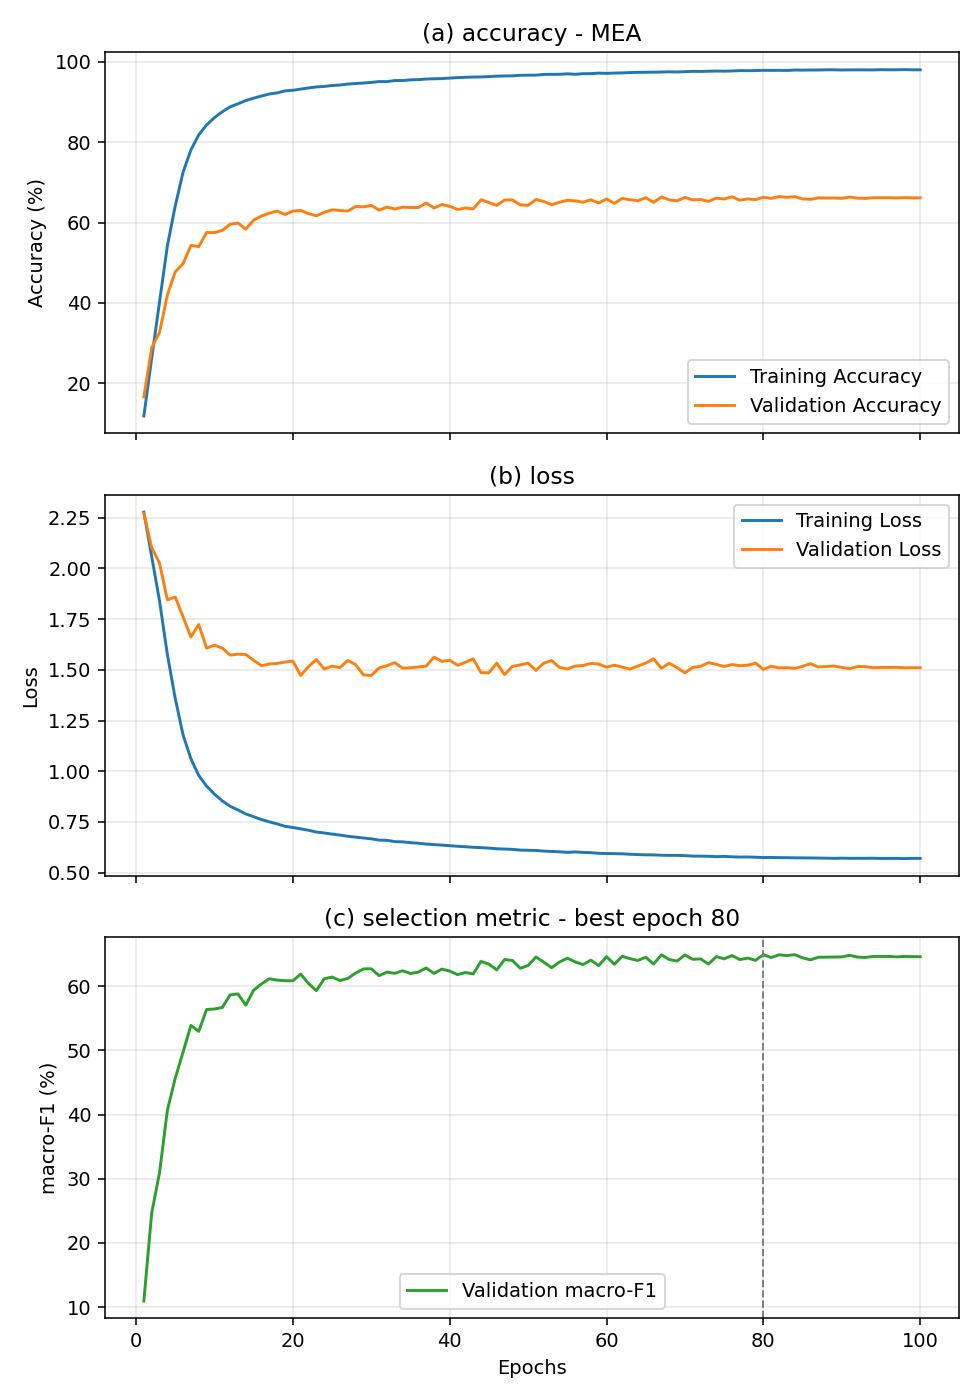

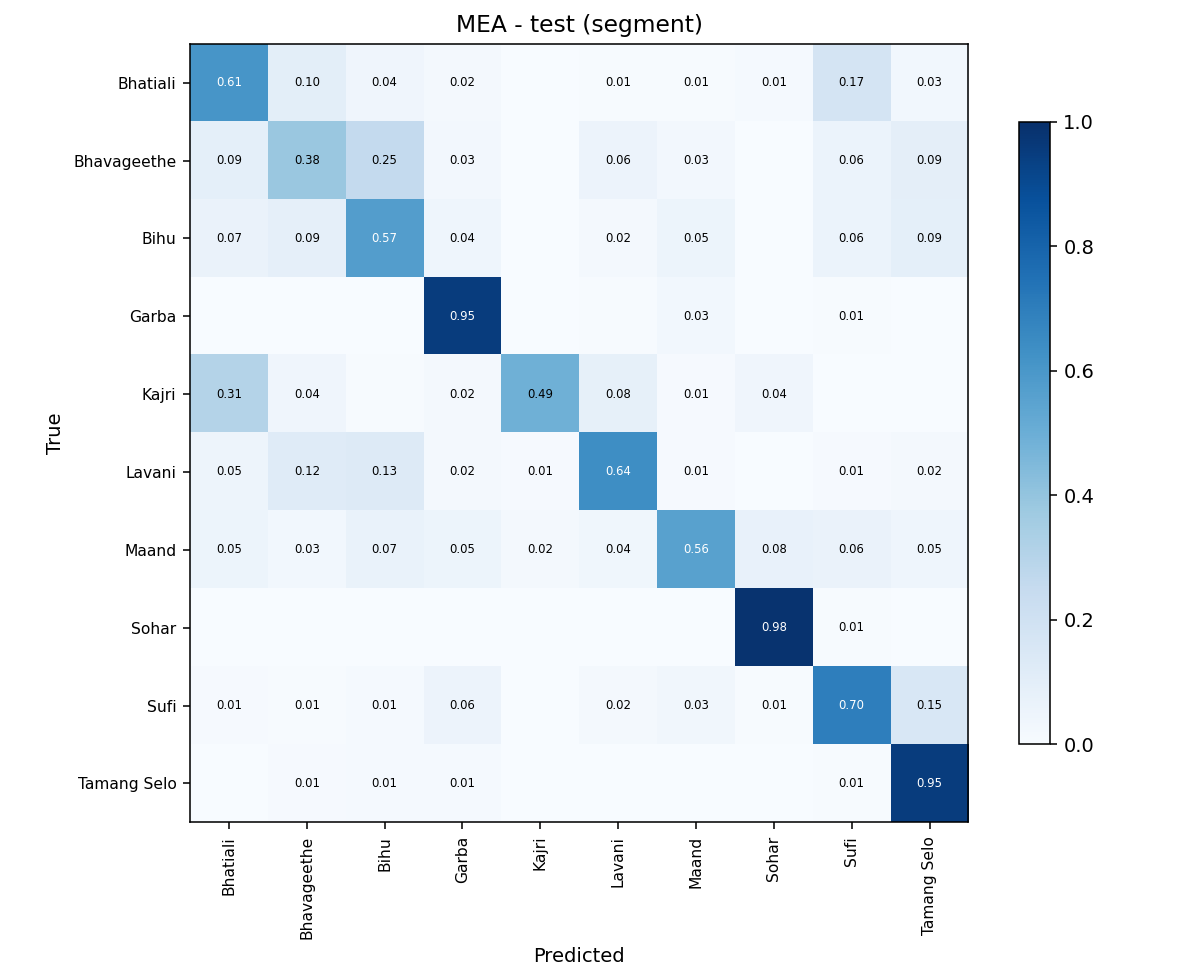

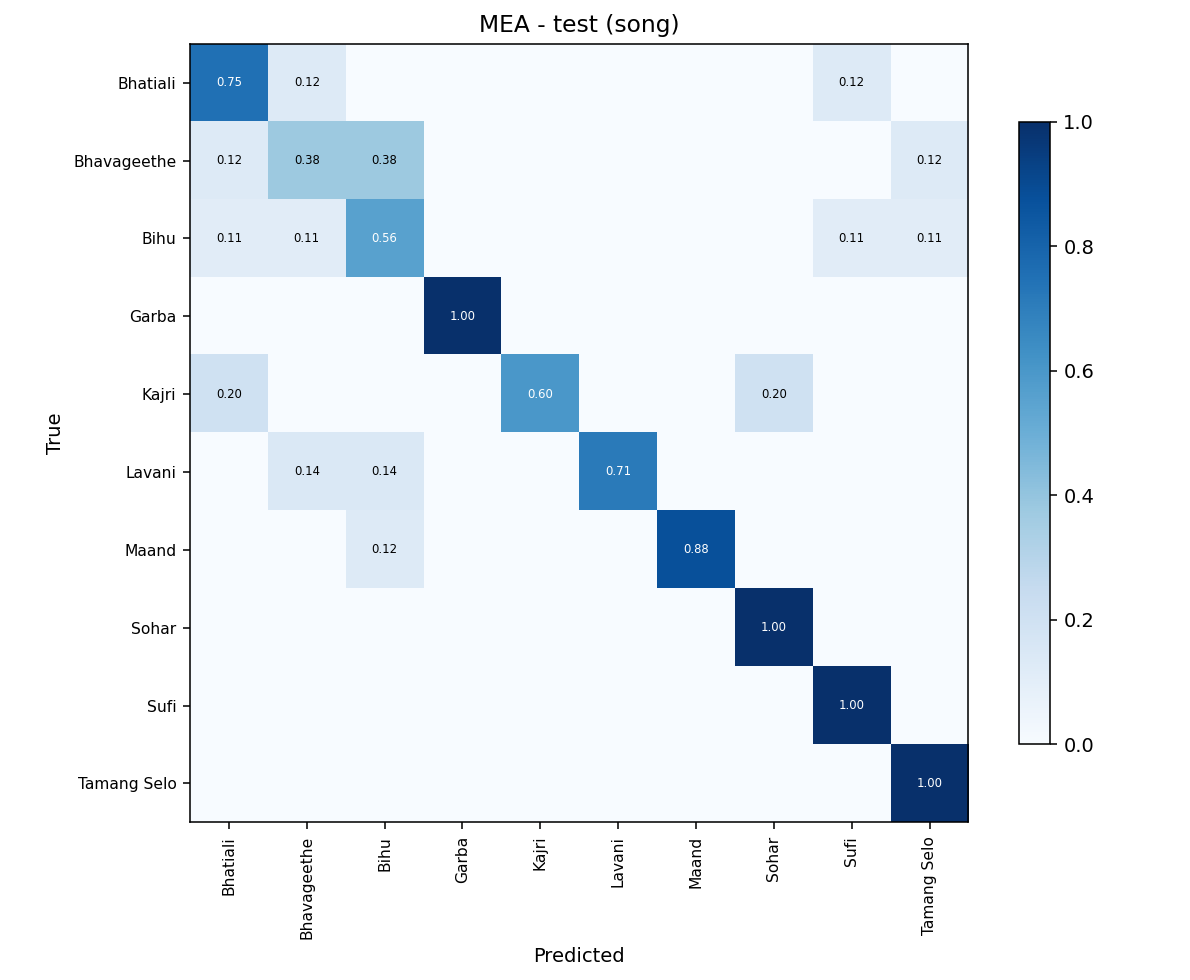

In [30]:
from IPython.display import Image, display
for name in ["curves.png", "confusion_test_segment.png", "confusion_test_song.png"]:
    path = f"{exp.train.out}/{name}"
    try:
        display(Image(filename=path))
    except Exception as exc:
        print(f"{name}: {exc}")

## 7. The splits ablation

This is the table worth putting in a write-up. The same model under three protocols:
the paper's random segment split, a song-grouped split, and an artist-grouped split.
The drop from the first to the third is the size of the leakage the original protocol
hides. Each row needs its own prepare stage, so this cell is slow - run it once the
main result is in hand.

In [31]:
import copy
results = {}
for group_key in ["none", "song", "artist"]:
    ab = copy.deepcopy(exp)
    ab.prep.group_key = group_key
    ab.prep.out = f"/kaggle/working/prep_{tag}_{group_key}"
    ab.cache.path = f"/kaggle/working/cache/{tag}_{group_key}.f16.npy"
    ab.train.out = f"/kaggle/working/runs/eavit_{tag}_{group_key}"
    ab.train.epochs = 40                     # shorter: this compares protocols, not models
    m, mt, c = run_prepare(ab)
    results[group_key] = run_training(ab, m, mt, c)
    del c

compare([f"/kaggle/working/runs/eavit_{tag}_{k}" for k in results],
        save_to=f"/kaggle/working/split_ablation_{tag}.csv")


Stage 1: preparing /kaggle/input/datasets
found 15 genre folders

genre                  rows  corrupt     kept  after stride
-----------------------------------------------------------
Bauls                20,223        0   20,223        20,223
Bhatiali             24,282       41   24,241        24,241
Bhavageethe          27,487       25   27,462        27,462
Bihu                 28,018       17   28,001        28,001
Garba                31,177        2   31,175        31,175
Gidha                18,735        0   18,735        18,735
Kajri                28,976        0   28,976        28,976
Lavani               24,724       60   24,664        24,664
Maand                33,789       20   33,769        33,769
Naatupura_Paatu       7,788       40    7,748         7,748
Sohar                30,821        0   30,821        30,821
Sufi                 38,895        4   38,891        38,891
Tamang_Selo          37,298       17   37,281        37,281
Uttarakhandi         17,872      

RuntimeError: cache needs 9.46 GB but only 9.9 GB free. Increase PrepConfig.stride, or set CacheConfig.enabled=False.

## 8. Notes for the write-up

- Report **song-level** accuracy as the headline, with the recording count next to it.
  Segment-level accuracy on overlapping windows overstates what the model can do.
- Report **macro-F1** alongside accuracy. Segment counts scale with recording duration,
  so accuracy is carried by a few long styles.
- With 16-50 recordings per style, a test split for the smallest class is 2-3 recordings.
  Run 3-5 seeds (`exp.prep.seed`, `exp.train.seed`) and quote mean +/- std.
- Do not expect the paper's 93.99% under a grouped split. That number comes from a random
  segment split on 10 well-separated Western genres with far more independent recordings.
  The honest number plus the split ablation in section 7 is the stronger result.
- State the class-selection rule verbatim: the ten styles with the most segments after
  cleaning and striding, chosen before any split or training. Name the five dropped
  styles and give the cut-off. A subset chosen on results is not an estimate of anything,
  and a reviewer will assume the worst if the rule is missing.
- `worst_artists_test.csv` in each run directory shows where errors concentrate. If a few
  artists carry most of the loss, the model is keying on recording conditions, not style.